<a href="https://colab.research.google.com/github/praveena161/CSA4710-DL/blob/main/CSA4710_LAB_PROGRAMS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1

In [ ]:
import numpy as np

# Grayscale image matrix
image = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

print("Original Image:")
print(image)

# Flatten matrix into vector
X = image.flatten()
print("\nFlattened Vector:")
print(X)

# Normalize values
X = X / 255

# Weight matrix
W = np.array([
    [0.2, 0.3],
    [0.4, 0.5],
    [0.6, 0.7],
    [0.1, 0.2],
    [0.3, 0.4],
    [0.5, 0.6],
    [0.7, 0.8],
    [0.2, 0.3],
    [0.4, 0.5]
])

# Bias
b = np.array([0.1, 0.2])

# Matrix multiplication
Z = np.dot(X, W) + b

# ReLU activation
output = np.maximum(0, Z)

print("\nLayer Output:")
print(output)

Original Image:
[[10 20 30]
 [40 50 60]
 [70 80 90]]

Flattened Vector:
[10 20 30 40 50 60 70 80 90]

Layer Output:
[0.79803922 1.0745098 ]


2

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Marks of five students
Maths = np.array([85, 90, 78, 92, 88])
Physics = np.array([80, 85, 75, 89, 90])
Computer = np.array([90, 95, 80, 94, 92])

# Calculate total marks
Total = Maths + Physics + Computer
print("Total Marks:", Total)

# Calculate average marks
Average = Total / 3
print("Average Marks:", Average)

# Highest average
student = np.argmax(Average)
print("Highest Average:", Average[student])
print("Top Student: Student", student + 1)

# Element-wise multiplication
result = Maths * Physics
print("Element-wise Multiplication:", result)

# Subject-wise average
subject_avg = [
    np.mean(Maths),
    np.mean(Physics),
    np.mean(Computer)
]

print("Subject Averages:", subject_avg)

# Bar chart
subjects = ['Mathematics', 'Physics', 'Computer Science']

plt.bar(subjects, subject_avg)
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.title("Subject-wise Average Marks")
plt.show()

3

Prior Probability: 0.01
Sensitivity: 0.99
False Positive Rate: 0.05
Probability of Positive Test: 0.0594
Posterior Probability: 0.16666666666666669
Percentage: 16.666666666666668 %


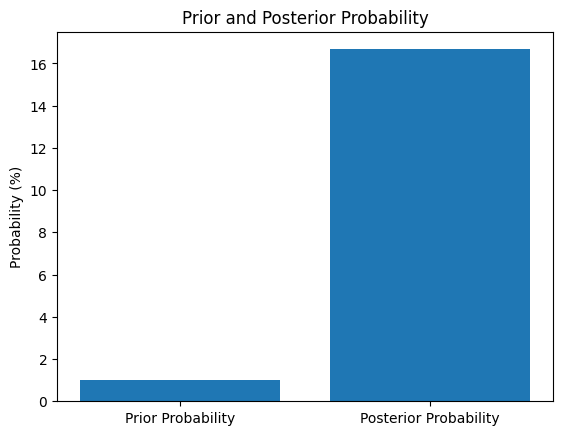

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Prior probability
P_D = 0.01

# Probability of not having disease
P_ND = 1 - P_D

# Sensitivity
P_Pos_D = 0.99

# False positive rate
P_Pos_ND = 0.05

# Bayes' Theorem
P_Pos = (P_Pos_D * P_D) + (P_Pos_ND * P_ND)

P_D_Pos = (P_Pos_D * P_D) / P_Pos

# Display results
print("Prior Probability:", P_D)
print("Sensitivity:", P_Pos_D)
print("False Positive Rate:", P_Pos_ND)
print("Probability of Positive Test:", P_Pos)
print("Posterior Probability:", P_D_Pos)
print("Percentage:", P_D_Pos * 100, "%")

# Visualization
labels = ['Prior Probability', 'Posterior Probability']
values = [P_D * 100, P_D_Pos * 100]

plt.bar(labels, values)
plt.ylabel("Probability (%)")
plt.title("Prior and Posterior Probability")
plt.show()

4

Entropy using SciPy: 1.4854752972273346
Entropy using NumPy: 1.4854752972273344


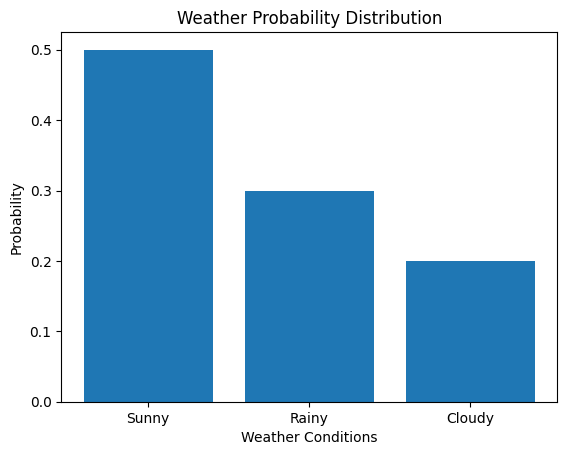

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# Probability distribution
P = np.array([0.5, 0.3, 0.2])

# Entropy using SciPy
H1 = entropy(P, base=2)

# Entropy using NumPy
H2 = -np.sum(P * np.log2(P))

print("Entropy using SciPy:", H1)
print("Entropy using NumPy:", H2)

# Bar chart
weather = ['Sunny', 'Rainy', 'Cloudy']

plt.bar(weather, P)
plt.xlabel("Weather Conditions")
plt.ylabel("Probability")
plt.title("Weather Probability Distribution")
plt.show()

5


Polynomial Degree: 1
Training Error: 21.191971410524264
Testing Error: 16.342487842925067

Polynomial Degree: 2
Training Error: 20.36788425854079
Testing Error: 15.896015182052011

Polynomial Degree: 10
Training Error: 19.25961408607035
Testing Error: 16.530089290734143


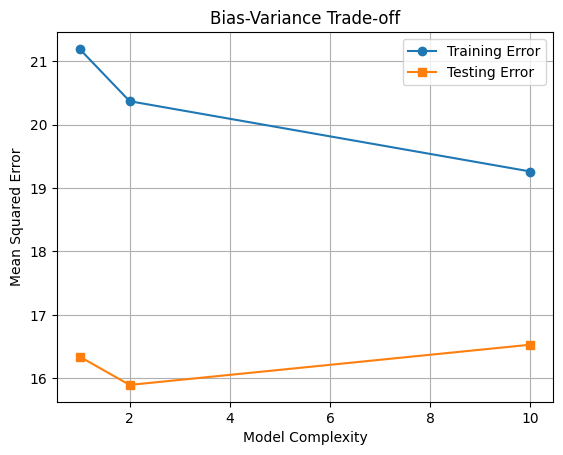

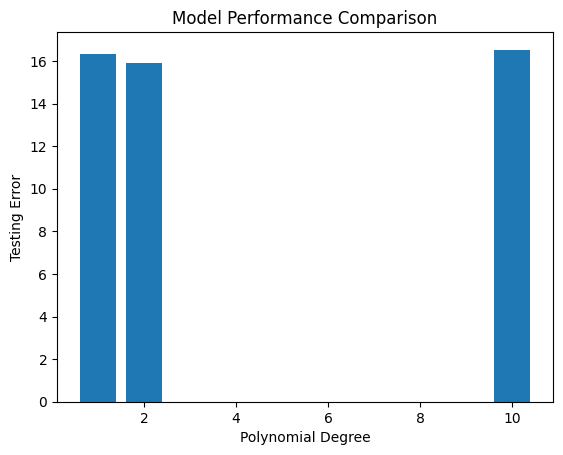

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Generate student performance dataset
np.random.seed(42)

X = np.random.rand(100, 1) * 10
y = 5 * X.ravel() + np.random.randn(100) * 5

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

degrees = [1, 2, 10]
train_errors = []
test_errors = []

# Train models with different complexities
for degree in degrees:

    poly = PolynomialFeatures(degree=degree)

    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # Predictions
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    train_errors.append(train_mse)
    test_errors.append(test_mse)

    print("\nPolynomial Degree:", degree)
    print("Training Error:", train_mse)
    print("Testing Error:", test_mse)

# Plot errors
plt.plot(degrees, train_errors, marker='o', label='Training Error')
plt.plot(degrees, test_errors, marker='s', label='Testing Error')

plt.xlabel("Model Complexity")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Trade-off")
plt.legend()
plt.grid()
plt.show()

# Compare errors
plt.bar(degrees, test_errors)
plt.xlabel("Polynomial Degree")
plt.ylabel("Testing Error")
plt.title("Model Performance Comparison")
plt.show()

6

Gradient Descent Loss: 148.1032921304253
SGD Loss: 6.181755935244443e-06
Momentum Loss: 8.424680099997365
Adam Loss: 489958.2746949123


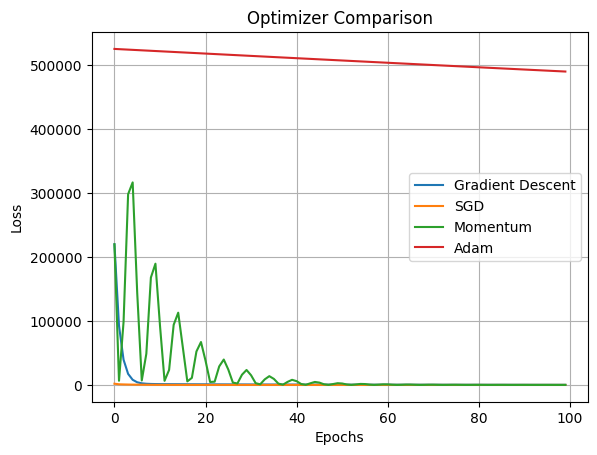

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate house price dataset
np.random.seed(42)

X = np.random.rand(100, 3)

# Features: Area, Bedrooms, Location
y = 500 + 200 * X[:, 0] + 100 * X[:, 1] + 150 * X[:, 2]

# Initialize parameters
def initialize():
    return np.zeros(3), 0.0

# Mean Squared Error
def calculate_loss(X, y, w, b):
    pred = np.dot(X, w) + b
    return np.mean((pred - y) ** 2)

# Gradient Descent
def gradient_descent(X, y, lr=0.1, epochs=100):
    w, b = initialize()
    losses = []

    for i in range(epochs):
        pred = np.dot(X, w) + b
        error = pred - y

        dw = 2 * np.dot(X.T, error) / len(y)
        db = 2 * np.mean(error)

        w -= lr * dw
        b -= lr * db

        losses.append(calculate_loss(X, y, w, b))

    return losses

# Stochastic Gradient Descent
def sgd(X, y, lr=0.01, epochs=100):
    w, b = initialize()
    losses = []

    for i in range(epochs):
        for j in np.random.permutation(len(y)):
            pred = np.dot(X[j], w) + b
            error = pred - y[j]

            dw = 2 * error * X[j]
            db = 2 * error

            w -= lr * dw
            b -= lr * db

        losses.append(calculate_loss(X, y, w, b))

    return losses

# Momentum
def momentum(X, y, lr=0.1, epochs=100):
    w, b = initialize()
    vw = np.zeros(3)
    vb = 0.0
    beta = 0.9
    losses = []

    for i in range(epochs):
        pred = np.dot(X, w) + b
        error = pred - y

        dw = 2 * np.dot(X.T, error) / len(y)
        db = 2 * np.mean(error)

        vw = beta * vw + dw
        vb = beta * vb + db

        w -= lr * vw
        b -= lr * vb

        losses.append(calculate_loss(X, y, w, b))

    return losses

# Adam Optimizer
def adam(X, y, lr=0.1, epochs=100):
    w, b = initialize()

    mw = np.zeros(3)
    vw = np.zeros(3)
    mb = 0.0
    vb = 0.0

    beta1 = 0.9
    beta2 = 0.999
    epsilon = 1e-8
    losses = []

    for t in range(1, epochs + 1):
        pred = np.dot(X, w) + b
        error = pred - y

        dw = 2 * np.dot(X.T, error) / len(y)
        db = 2 * np.mean(error)

        mw = beta1 * mw + (1 - beta1) * dw
        vw = beta2 * vw + (1 - beta2) * (dw ** 2)

        mb = beta1 * mb + (1 - beta1) * db
        vb = beta2 * vb + (1 - beta2) * (db ** 2)

        mw_hat = mw / (1 - beta1 ** t)
        vw_hat = vw / (1 - beta2 ** t)

        mb_hat = mb / (1 - beta1 ** t)
        vb_hat = vb / (1 - beta2 ** t)

        w -= lr * mw_hat / (np.sqrt(vw_hat) + epsilon)
        b -= lr * mb_hat / (np.sqrt(vb_hat) + epsilon)

        losses.append(calculate_loss(X, y, w, b))

    return losses

# Train all optimizers
gd_loss = gradient_descent(X, y)
sgd_loss = sgd(X, y)
mom_loss = momentum(X, y)
adam_loss = adam(X, y)

# Display final losses
print("Gradient Descent Loss:", gd_loss[-1])
print("SGD Loss:", sgd_loss[-1])
print("Momentum Loss:", mom_loss[-1])
print("Adam Loss:", adam_loss[-1])

# Plot loss curves
plt.plot(gd_loss, label="Gradient Descent")
plt.plot(sgd_loss, label="SGD")
plt.plot(mom_loss, label="Momentum")
plt.plot(adam_loss, label="Adam")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Optimizer Comparison")
plt.legend()
plt.grid()
plt.show()

7

Actual Output: [0 0 0 1 1 1]
Predicted Output: [0 1 0 1 1 1]
Accuracy: 83.33333333333334 %


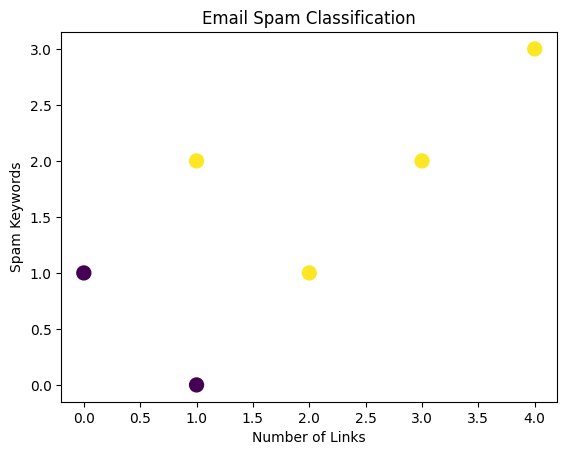

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create email dataset
# Features: Number of links, Spam keywords
X = np.array([
    [1, 0],
    [2, 1],
    [0, 1],
    [3, 2],
    [1, 2],
    [4, 3]
])

# Actual output (0 = Not Spam, 1 = Spam)
y = np.array([0, 0, 0, 1, 1, 1])

# Initialize weights and bias
weights = np.array([0.5, 0.5])
bias = -1.0

# Step activation function
def activation(x):
    return np.where(x >= 0, 1, 0)

# Forward propagation
z = np.dot(X, weights) + bias

# Predicted output
y_pred = activation(z)

# Display results
print("Actual Output:", y)
print("Predicted Output:", y_pred)

# Compare results
accuracy = np.mean(y == y_pred) * 100
print("Accuracy:", accuracy, "%")

# Visualization
plt.scatter(X[:, 0], X[:, 1], c=y_pred, s=100)
plt.xlabel("Number of Links")
plt.ylabel("Spam Keywords")
plt.title("Email Spam Classification")
plt.show()

8

Final Predictions:
[[0]
 [0]
 [1]
 [1]
 [1]
 [0]]

Actual Output:
[[0]
 [0]
 [1]
 [1]
 [1]
 [0]]

Initial Loss: 0.8322024897695298
Final Loss: 0.22543090913240027


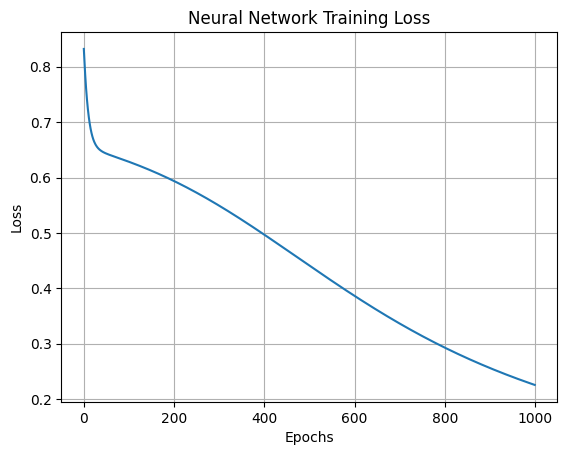

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Generate patient dataset
np.random.seed(42)

X = np.array([
    [0.2, 0.3],
    [0.4, 0.5],
    [0.6, 0.7],
    [0.8, 0.9],
    [0.3, 0.8],
    [0.9, 0.2]
])

# Actual class labels
y = np.array([[0], [0], [1], [1], [1], [0]])

# Initialize weights and biases
W1 = np.random.randn(2, 3)
b1 = np.zeros((1, 3))

W2 = np.random.randn(3, 1)
b2 = np.zeros((1, 1))

# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Learning rate
lr = 0.1

# Training
losses = []

for epoch in range(1000):

    # Forward propagation
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    # Calculate loss
    loss = -np.mean(
        y * np.log(A2 + 1e-8) +
        (1-y) * np.log(1-A2 + 1e-8)
    )

    losses.append(loss)

    # Backpropagation
    dZ2 = A2 - y
    dW2 = np.dot(A1.T, dZ2) / len(X)
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * A1 * (1-A1)

    dW1 = np.dot(X.T, dZ1) / len(X)
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Update weights and biases
    W2 -= lr * dW2
    b2 -= lr * db2

    W1 -= lr * dW1
    b1 -= lr * db1

# Final prediction
print("Final Predictions:")
print((A2 >= 0.5).astype(int))

print("\nActual Output:")
print(y)

print("\nInitial Loss:", losses[0])
print("Final Loss:", losses[-1])

# Plot loss
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Neural Network Training Loss")
plt.grid()
plt.show()

9

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9226 - loss: 0.2615 - val_accuracy: 0.9647 - val_loss: 0.1200
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9679 - loss: 0.1058 - val_accuracy: 0.9710 - val_loss: 0.0971
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9762 - loss: 0.0756 - val_accuracy: 0.9777 - val_loss: 0.0799
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9831 - loss: 0.0552 - val_accuracy: 0.9797 - val_loss: 0.0847
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 26s 12ms/step - accuracy: 0.9861 - loss: 0.0449 - val_accuracy: 0.9753 - val_loss: 0.0916
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9734 - loss: 0.0930
Test Loss: 0.09300289303064346
Test Accuracy: 97.33999967575073 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Actual Labels: [7 2 1 0 4]
Predicted Labels: [7 2 1 0 4]


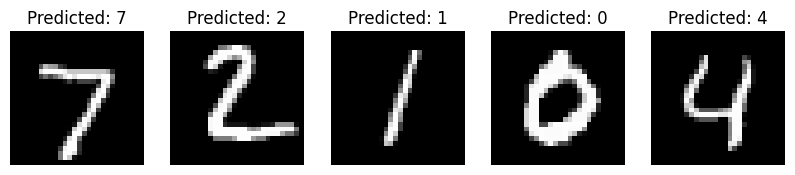

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


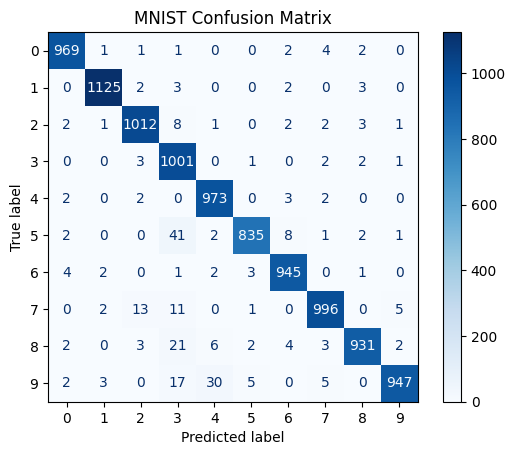

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize image data
x_train = x_train / 255.0
x_test = x_test / 255.0

# Display dataset shape
print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# Build MLP model
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

# Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Predict digits
predictions = model.predict(x_test[:5])
predicted_labels = np.argmax(predictions, axis=1)

print("Actual Labels:", y_test[:5])
print("Predicted Labels:", predicted_labels)

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Predicted: {predicted_labels[i]}")
    plt.axis('off')

plt.show()

# Confusion Matrix
y_pred = np.argmax(model.predict(x_test), axis=1)

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("MNIST Confusion Matrix")
plt.show()

10


Training: Baseline
Test Loss: 0.07213986665010452
Test Accuracy: 98.00000190734863 %

Training: L2
Test Loss: 0.12771880626678467
Test Accuracy: 98.00000190734863 %

Training: Dropout
Test Loss: 0.07373456656932831
Test Accuracy: 98.00000190734863 %

Training: Early Stopping
Test Loss: 0.06552539765834808
Test Accuracy: 99.00000095367432 %


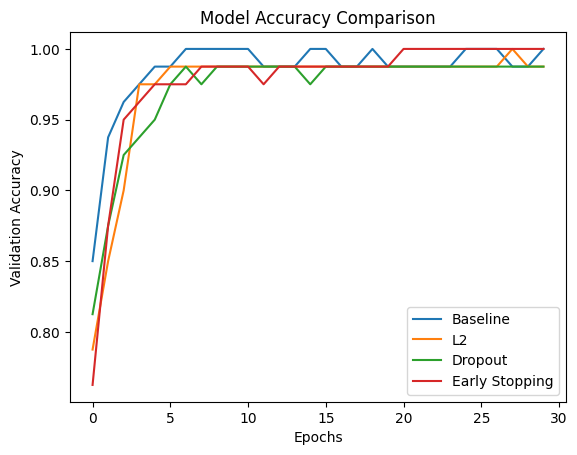

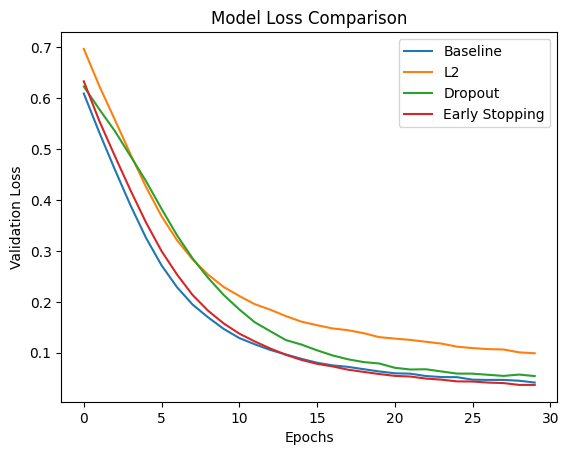

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate student dataset
np.random.seed(42)

X = np.random.rand(500, 4)

# Features: Attendance, Internal Marks, Assignment, Study Hours
y = (X[:, 0] + X[:, 1] + X[:, 2] + X[:, 3] > 2).astype(int)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Function to create model
def create_model(regularization=None, dropout=False):

    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(4,)))

    if regularization == "l2":
        model.add(tf.keras.layers.Dense(
            64, activation='relu',
            kernel_regularizer=tf.keras.regularizers.l2(0.01)
        ))
    else:
        model.add(tf.keras.layers.Dense(64, activation='relu'))

    if dropout:
        model.add(tf.keras.layers.Dropout(0.5))

    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Create models
models = {
    "Baseline": create_model(),
    "L2": create_model(regularization="l2"),
    "Dropout": create_model(dropout=True),
    "Early Stopping": create_model()
}

histories = {}

# Train models
for name, model in models.items():

    callbacks = []

    if name == "Early Stopping":
        callbacks.append(
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=5,
                restore_best_weights=True
            )
        )

    print("\nTraining:", name)

    histories[name] = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        callbacks=callbacks,
        verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy * 100, "%")

# Plot training and validation accuracy
for name, history in histories.items():
    plt.plot(history.history['val_accuracy'], label=name)

plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Model Accuracy Comparison")
plt.legend()
plt.show()

# Plot training and validation loss
for name, history in histories.items():
    plt.plot(history.history['val_loss'], label=name)

plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.title("Model Loss Comparison")
plt.legend()
plt.show()

11


In [ ]:
!pip install tensorflow-datasets

In [ ]:
!pip install -q importlib_resources

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("Loading PlantVillage Dataset...")

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True,
    data_dir="/content/plant_village_data"
)

print("Dataset Loaded Successfully!")
print("Number of Classes:", info.features["label"].num_classes)

Loading PlantVillage Dataset...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

12

In [ ]:
!pip install -q datasets

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from datasets import load_dataset
from PIL import Image
from sklearn.model_selection import train_test_split

In [ ]:
print("Loading Traffic Sign Dataset...")

dataset = load_dataset("tanganke/gtsrb")

print(dataset)

train_data = dataset["train"]
test_data = dataset["test"]

print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))

Loading Traffic Sign Dataset...


README.md:   0%|          | 0.00/8.52k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  224MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  109MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (20 outputs left out)

Generating motion_blur split:   0%|          | 0/12630 [00:00<?, ? examples/s]

Generating pixelate split:   0%|          | 0/12630 [00:00<?, ? examples/s]

Generating spatter split:   0%|          | 0/12630 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 26640
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    contrast: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    gaussian_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    impulse_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    jpeg_compression: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    motion_blur: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    pixelate: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    spatter: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
})
Training Samples: 26640
Testing Samples: 12630


In [ ]:
def preprocess_images(data):

    images = []
    labels = []

    for item in data:

        img = item["image"].convert("RGB")
        img = img.resize((32, 32))

        img = np.array(img, dtype="float32") / 255.0

        images.append(img)
        labels.append(item["label"])

    return np.array(images), np.array(labels)


X = np.concatenate([
    preprocess_images(train_data)[0],
    preprocess_images(test_data)[0]
])

y = np.concatenate([
    preprocess_images(train_data)[1],
    preprocess_images(test_data)[1]
])

print("Dataset Shape:", X.shape)
print("Labels Shape:", y.shape)
print("Number of Classes:", len(np.unique(y)))

Dataset Shape: (39270, 32, 32, 3)
Labels Shape: (39270,)
Number of Classes: 43


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

num_classes = len(np.unique(y))

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Training Data: (25132, 32, 32, 3)
Validation Data: (6284, 32, 32, 3)
Testing Data: (7854, 32, 32, 3)


13

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.1303 - val_loss: 0.0775
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0419 - val_loss: 0.0271
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0244 - val_loss: 0.0147
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0118 - val_loss: 0.0056
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0064 - val_loss: 0.0038
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0048 - val_loss: 0.0037
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0037 - val_loss: 0.0039
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0041 - val_loss: 0.0036
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0034 - val_loss: 0.0033
Epoch 10/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0034 - val_loss: 0.0031
Epoch 11/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 0.0034 - val_loss: 0.0032
Epoch 12/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0033 - val_l

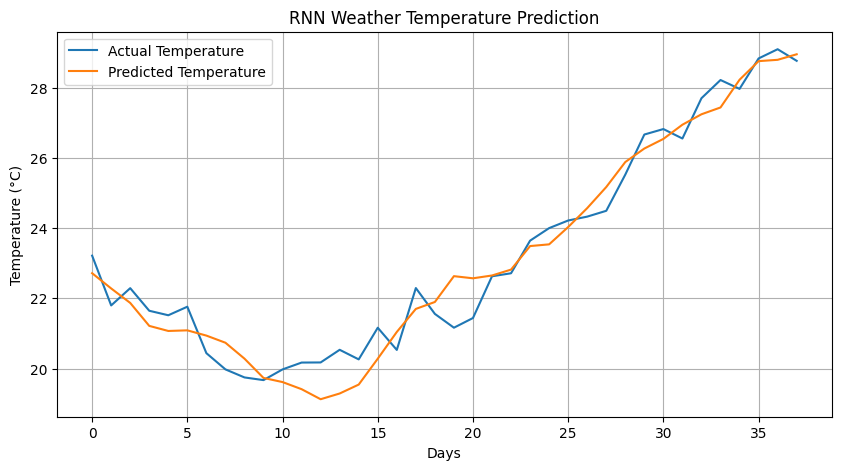

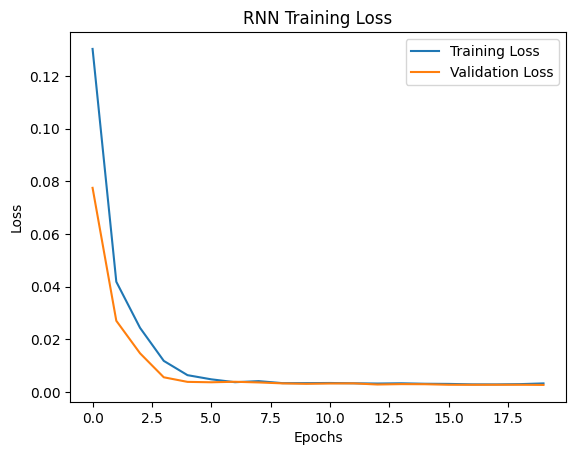

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

# Generate temperature dataset
np.random.seed(42)

temperature = 25 + 5 * np.sin(np.arange(200) * 0.1)
temperature += np.random.normal(0, 0.5, 200)

# Reshape dataset
temperature = temperature.reshape(-1, 1)

# Normalize data
scaler = MinMaxScaler()
data = scaler.fit_transform(temperature)

# Create input sequences
X = []
y = []

for i in range(len(data) - 10):
    X.append(data[i:i+10])
    y.append(data[i+10])

X = np.array(X)
y = np.array(y)

# Split dataset
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# Build RNN model
model = tf.keras.Sequential([
    tf.keras.layers.SimpleRNN(
        50, activation='tanh',
        input_shape=(10, 1)
    ),
    tf.keras.layers.Dense(1)
])

# Compile model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# Predict temperature
predictions = model.predict(X_test)

# Convert to original scale
predictions = scaler.inverse_transform(predictions)
actual = scaler.inverse_transform(y_test)

# Display results
print("Actual Temperatures:")
print(actual[:10].flatten())

print("\nPredicted Temperatures:")
print(predictions[:10].flatten())

# Plot actual and predicted temperatures
plt.figure(figsize=(10, 5))

plt.plot(actual, label='Actual Temperature')
plt.plot(predictions, label='Predicted Temperature')

plt.xlabel("Days")
plt.ylabel("Temperature (°C)")
plt.title("RNN Weather Temperature Prediction")
plt.legend()
plt.grid()
plt.show()

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("RNN Training Loss")
plt.legend()
plt.show()

14

Time Step: 1
Input: AI
Hidden State: [0.35795651 0.74010626 0.62428371]
Output: 0.6184193177482362
Time Step: 2
Input: is
Hidden State: [0.93064415 0.54684316 0.8344199 ]
Output: 0.7749243355407489
Time Step: 3
Input: changing
Hidden State: [0.97097512 0.97052586 0.97212232]
Output: 0.9834836185442953
Time Step: 4
Input: the
Hidden State: [0.97330503 0.84066936 0.95246965]
Output: 0.9340902377886461
Time Step: 5
Input: world
Hidden State: [0.94875904 0.96495661 0.98031661]
Output: 0.9820146973920599
Time Step: 1
Input: AI
Hidden State: [0.35795651 0.74010626 0.62428371]
Output: 0.6184193177482362
Time Step: 2
Input: is
Hidden State: [0.93064415 0.54684316 0.8344199 ]
Output: 0.7749243355407489
Time Step: 3
Input: changing
Hidden State: [0.97097512 0.97052586 0.97212232]
Output: 0.9834836185442953
Time Step: 4
Input: the
Hidden State: [0.97330503 0.84066936 0.95246965]
Output: 0.9340902377886461
Time Step: 5
Input: world
Hidden State: [0.94875904 0.96495661 0.98031661]
Output: 0.9820146

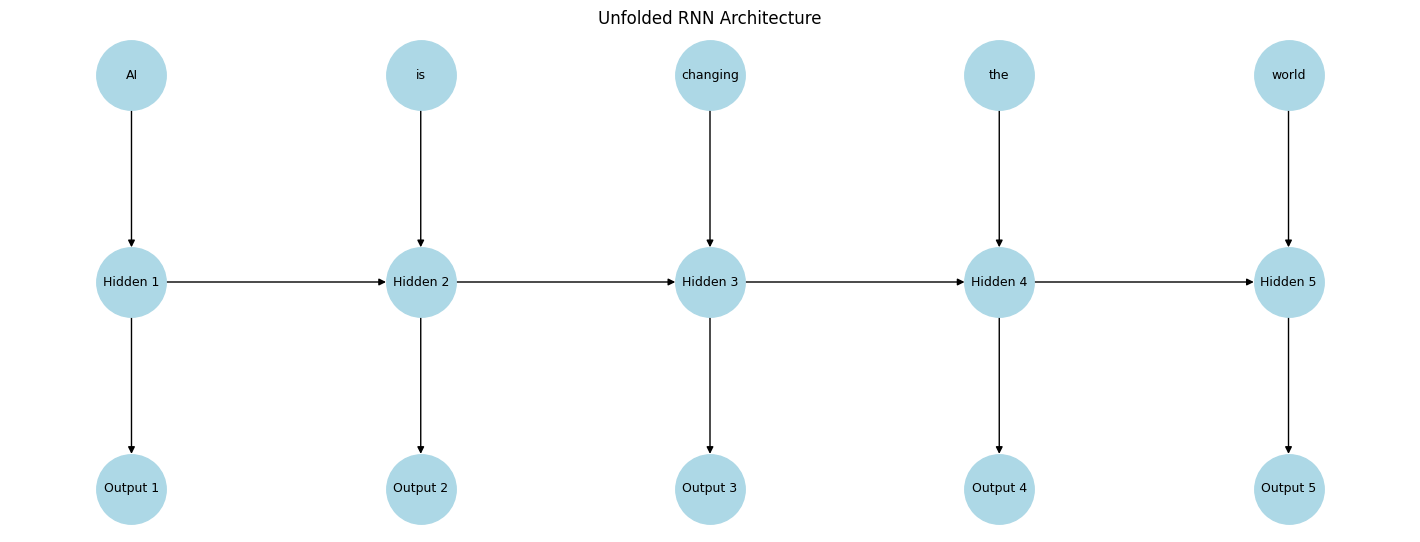

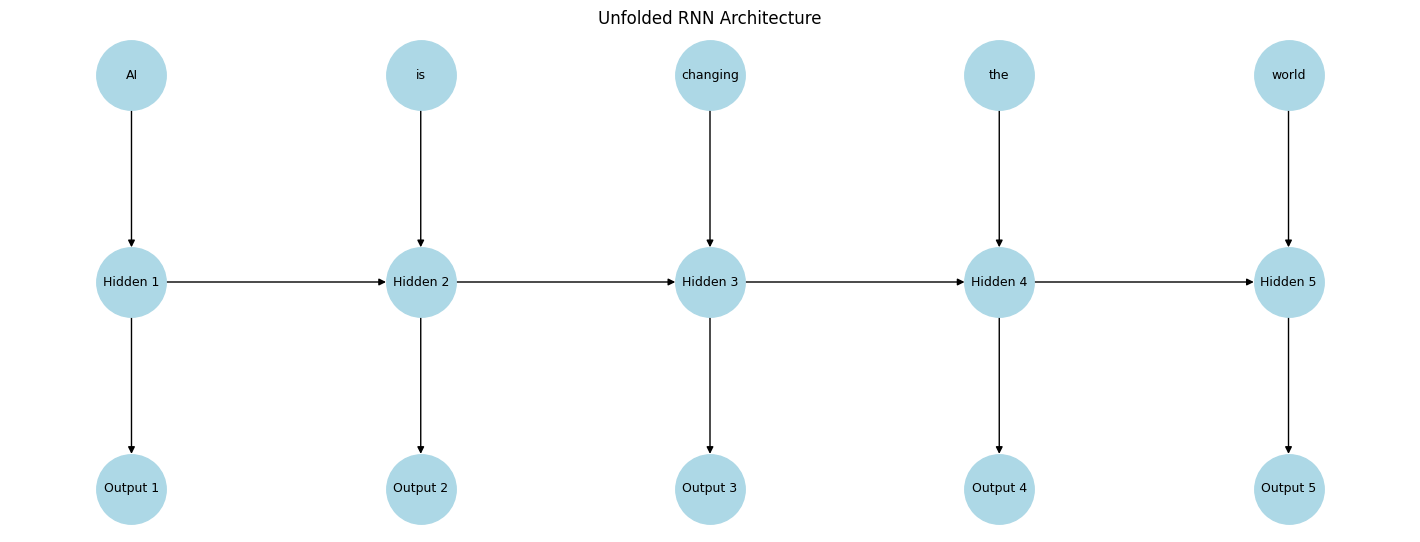

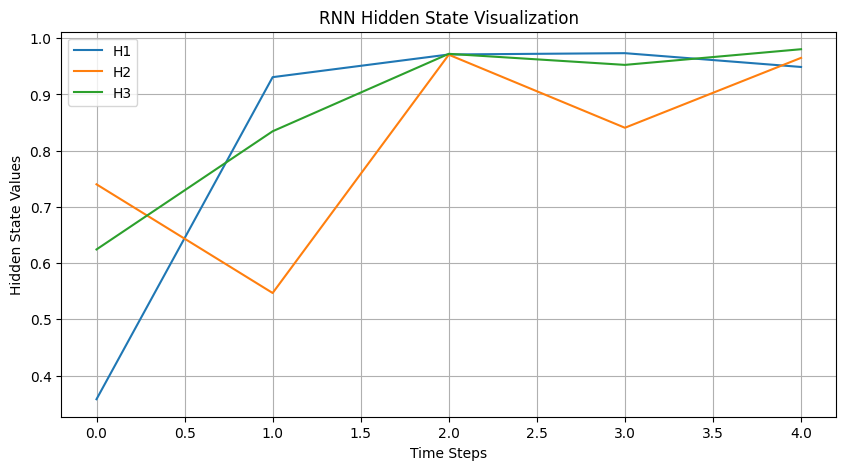

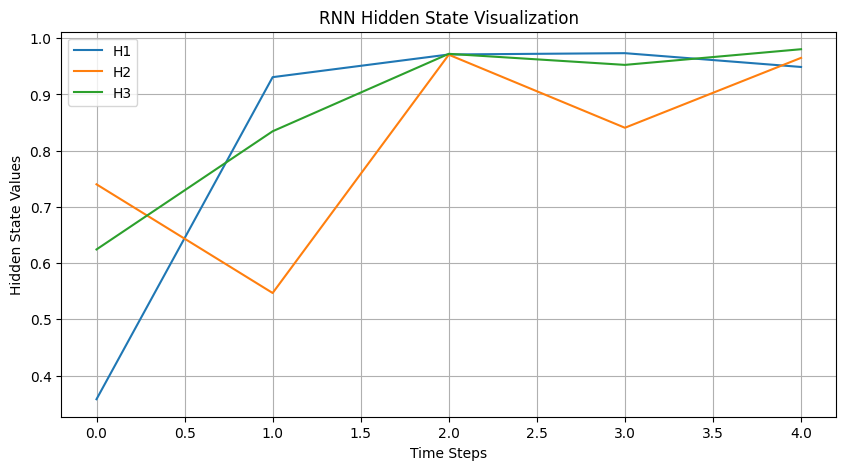

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Create a sample sequence
words = ['AI', 'is', 'changing', 'the', 'world']

# Convert words into numerical inputs
X = np.array([
    [1, 0],
    [0, 1],
    [1, 1],
    [0, 1],
    [1, 0]
])

# Initialize weights
np.random.seed(42)

Wx = np.random.rand(2, 3)
Wh = np.random.rand(3, 3)
Wy = np.random.rand(3, 1)

# Initialize hidden state
h = np.zeros(3)

# RNN forward propagation
hidden_states = []
outputs = []

for i in range(len(X)):

    h = np.tanh(np.dot(X[i], Wx) + np.dot(h, Wh))

    y = np.dot(h, Wy)

    hidden_states.append(h.copy())
    outputs.append(y[0])

    print("Time Step:", i + 1)
    print("Input:", words[i])
    print("Hidden State:", h)
    print("Output:", y[0])

# Visualize unfolded RNN
G = nx.DiGraph()

for i in range(len(words)):
    G.add_node(f"X{i+1}", label=words[i])
    G.add_node(f"H{i+1}", label=f"Hidden {i+1}")
    G.add_node(f"Y{i+1}", label=f"Output {i+1}")

    G.add_edge(f"X{i+1}", f"H{i+1}")
    G.add_edge(f"H{i+1}", f"Y{i+1}")

    if i > 0:
        G.add_edge(f"H{i}", f"H{i+1}")

# Draw graph
pos = {}

for i in range(len(words)):
    pos[f"X{i+1}"] = (i * 2, 2)
    pos[f"H{i+1}"] = (i * 2, 1)
    pos[f"Y{i+1}"] = (i * 2, 0)

labels = nx.get_node_attributes(G, 'label')

plt.figure(figsize=(14, 5))

nx.draw(
    G, pos,
    labels=labels,
    with_labels=True,
    node_size=2500,
    node_color='lightblue',
    font_size=9,
    arrows=True
)

plt.title("Unfolded RNN Architecture")
plt.show()

# Plot hidden states
plt.figure(figsize=(10, 5))

plt.plot(np.array(hidden_states))

plt.xlabel("Time Steps")
plt.ylabel("Hidden State Values")
plt.title("RNN Hidden State Visualization")
plt.legend(['H1', 'H2', 'H3'])
plt.grid()
plt.show()

15

Initial Loss: 0.3411100303370403
Loss After Weight Update: 0.3333274737861501
Gradient Values: [np.float64(0.039466311712854536), np.float64(0.05125010881499686), np.float64(0.05696195355416438), np.float64(0.05956014412296978), np.float64(0.05757734027991831)]


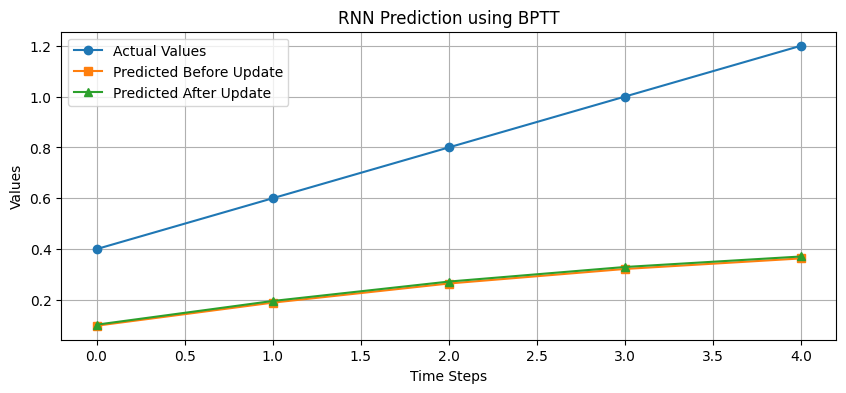

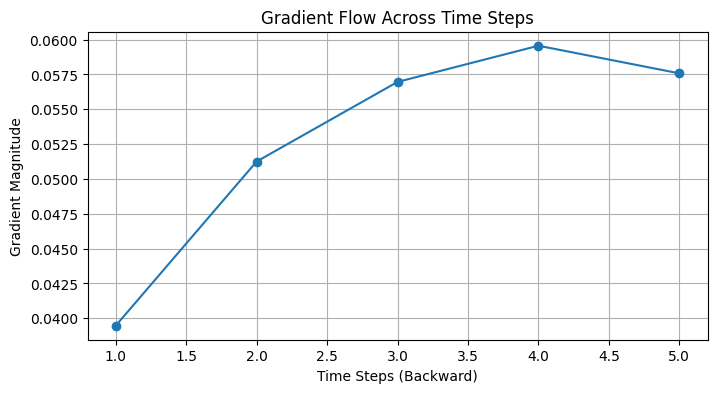

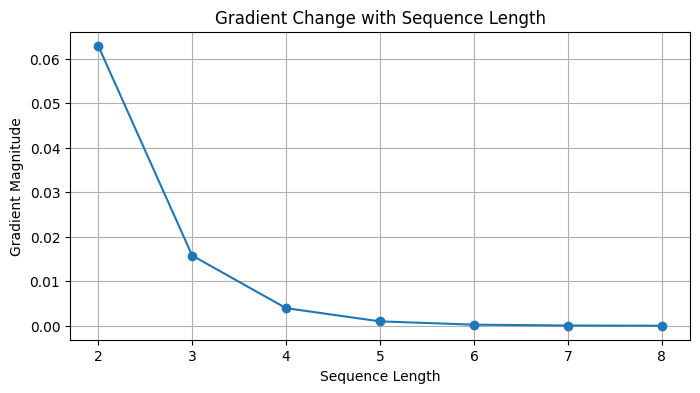

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate sequential dataset
X = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
Y = np.array([0.4, 0.6, 0.8, 1.0, 1.2])

# Initialize RNN weights
Wx = 0.5
Wh = 0.5
Wy = 0.5
b = 0.1

learning_rate = 0.01
hidden_size = 1

# Forward propagation
h = np.zeros(len(X) + 1)
y_pred = np.zeros(len(X))

for t in range(len(X)):
    h[t + 1] = np.tanh(Wx * X[t] + Wh * h[t] + b)
    y_pred[t] = Wy * h[t + 1]

# Calculate prediction error
loss = np.mean((Y - y_pred) ** 2)
print("Initial Loss:", loss)

# Backpropagation Through Time (BPTT)
dWx = 0
dWh = 0
dWy = 0
db = 0
dh_next = 0

gradient_values = []

for t in reversed(range(len(X))):
    dy = (2 / len(X)) * (y_pred[t] - Y[t])

    dWy += dy * h[t + 1]

    dh = dy * Wy + dh_next
    dz = dh * (1 - h[t + 1] ** 2)

    dWx += dz * X[t]
    dWh += dz * h[t]
    db += dz

    dh_next = dz * Wh
    gradient_values.append(abs(dh_next))

# Update weights
Wx -= learning_rate * dWx
Wh -= learning_rate * dWh
Wy -= learning_rate * dWy
b -= learning_rate * db

# Forward propagation after update
h = np.zeros(len(X) + 1)
y_new = np.zeros(len(X))

for t in range(len(X)):
    h[t + 1] = np.tanh(Wx * X[t] + Wh * h[t] + b)
    y_new[t] = Wy * h[t + 1]

new_loss = np.mean((Y - y_new) ** 2)

print("Loss After Weight Update:", new_loss)
print("Gradient Values:", gradient_values)

# Visualize actual and predicted values
plt.figure(figsize=(10, 4))
plt.plot(Y, marker='o', label='Actual Values')
plt.plot(y_pred, marker='s', label='Predicted Before Update')
plt.plot(y_new, marker='^', label='Predicted After Update')
plt.title("RNN Prediction using BPTT")
plt.xlabel("Time Steps")
plt.ylabel("Values")
plt.legend()
plt.grid()
plt.show()

# Visualize gradient flow
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(gradient_values) + 1),
         gradient_values, marker='o')
plt.title("Gradient Flow Across Time Steps")
plt.xlabel("Time Steps (Backward)")
plt.ylabel("Gradient Magnitude")
plt.grid()
plt.show()

# Analyze gradient changes with sequence length
sequence_lengths = [2, 3, 4, 5, 6, 7, 8]
gradient_magnitudes = []

for length in sequence_lengths:
    gradient = 1.0

    for i in range(length):
        gradient *= abs(Wh) * 0.5

    gradient_magnitudes.append(gradient)

plt.figure(figsize=(8, 4))
plt.plot(sequence_lengths, gradient_magnitudes, marker='o')
plt.title("Gradient Change with Sequence Length")
plt.xlabel("Sequence Length")
plt.ylabel("Gradient Magnitude")
plt.grid()
plt.show()

16

Predicted Values:
[[-0.00073247]
 [-0.00128247]
 [-0.00182647]
 [-0.00236938]
 [-0.00291205]]

Actual Values:
[[0.2]
 [0.3]
 [0.4]
 [0.5]
 [0.6]]

Initial Loss: 0.1816814191651678

Loss After Weight Update: 0.17483425937226915
Predicted Values:
[[-0.00073247]
 [-0.00128247]
 [-0.00182647]
 [-0.00236938]
 [-0.00291205]]

Actual Values:
[[0.2]
 [0.3]
 [0.4]
 [0.5]
 [0.6]]

Initial Loss: 0.1816814191651678

Loss After Weight Update: 0.17483425937226915


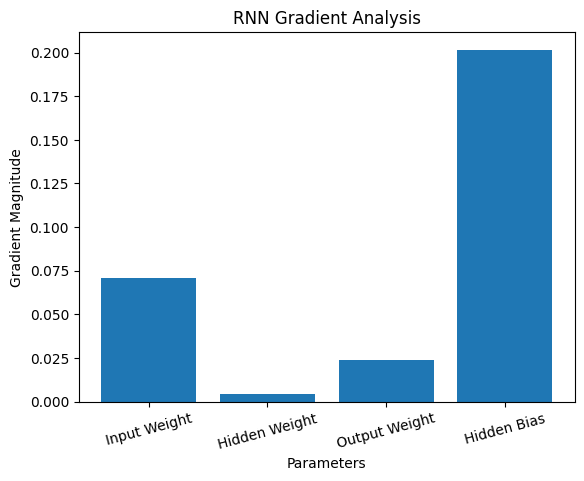

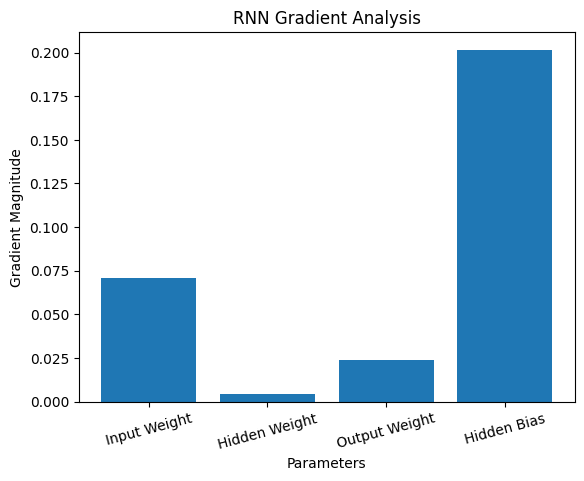

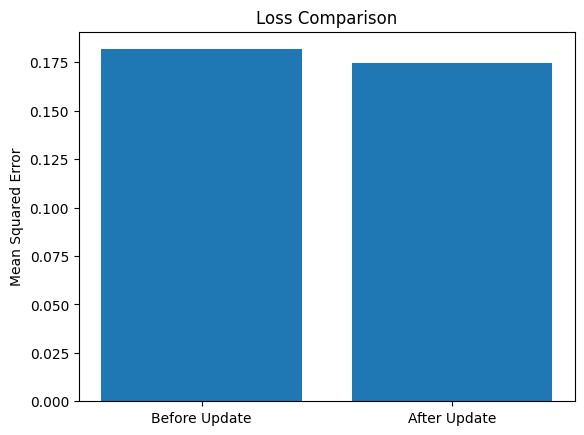

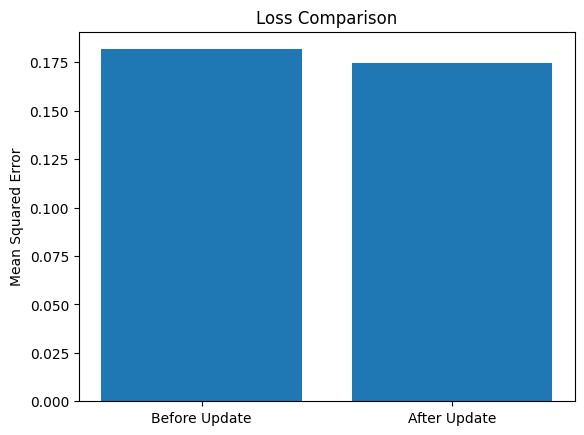

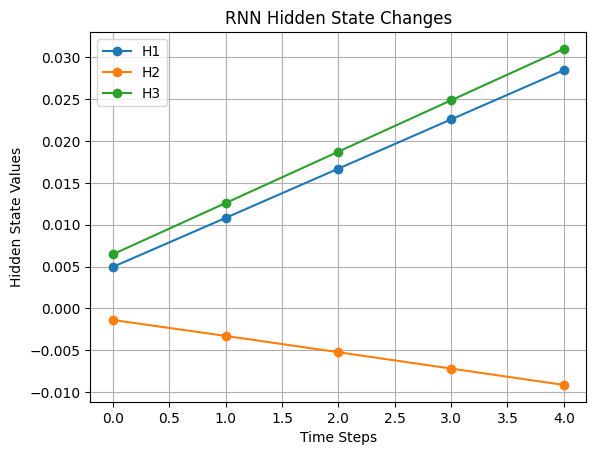

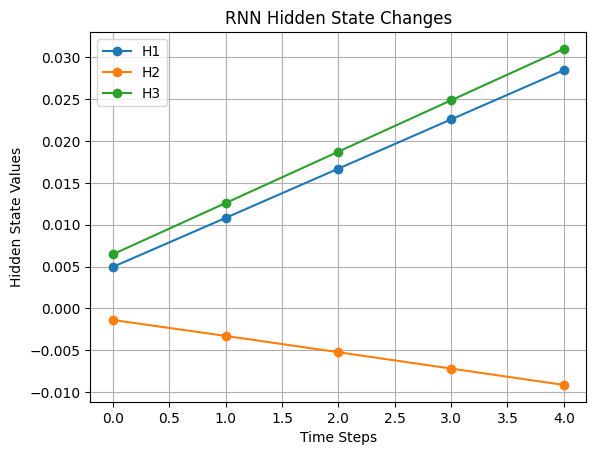

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create sequential dataset
X = np.array([[0.1], [0.2], [0.3], [0.4], [0.5]])
y = np.array([[0.2], [0.3], [0.4], [0.5], [0.6]])

# Initialize weights
np.random.seed(42)

Wx = np.random.randn(1, 3) * 0.1
Wh = np.random.randn(3, 3) * 0.1
Wy = np.random.randn(3, 1) * 0.1

bh = np.zeros((1, 3))
by = np.zeros((1, 1))

# Forward propagation
h = np.zeros((1, 3))
hidden_states = []
predictions = []

for t in range(len(X)):

    h = np.tanh(X[t].reshape(1, 1) @ Wx + h @ Wh + bh)

    output = h @ Wy + by

    hidden_states.append(h.copy())
    predictions.append(output.copy())

predictions = np.array(predictions).reshape(-1, 1)

# Calculate prediction error
loss = np.mean((predictions - y) ** 2)

print("Predicted Values:")
print(predictions)

print("\nActual Values:")
print(y)

print("\nInitial Loss:", loss)

# Backpropagation Through Time
dWx = np.zeros_like(Wx)
dWh = np.zeros_like(Wh)
dWy = np.zeros_like(Wy)

dbh = np.zeros_like(bh)
dby = np.zeros_like(by)

dh_next = np.zeros((1, 3))

# Backward through time
for t in reversed(range(len(X))):

    error = predictions[t].reshape(1, 1) - y[t].reshape(1, 1)

    dy = (2 / len(X)) * error

    dWy += hidden_states[t].T @ dy
    dby += dy

    dh = dy @ Wy.T + dh_next

    dz = dh * (1 - hidden_states[t] ** 2)

    dWx += X[t].reshape(1, 1).T @ dz
    dWh += (np.zeros((1, 3)) if t == 0 else hidden_states[t-1]).T @ dz
    dbh += dz

    dh_next = dz @ Wh.T

# Update weights
learning_rate = 0.01

Wx -= learning_rate * dWx
Wh -= learning_rate * dWh
Wy -= learning_rate * dWy

bh -= learning_rate * dbh
by -= learning_rate * dby

# Calculate loss after update
h = np.zeros((1, 3))
new_predictions = []

for t in range(len(X)):

    h = np.tanh(X[t].reshape(1, 1) @ Wx + h @ Wh + bh)

    output = h @ Wy + by
    new_predictions.append(output[0, 0])

new_loss = np.mean((np.array(new_predictions).reshape(-1, 1) - y) ** 2)

print("\nLoss After Weight Update:", new_loss)

# Gradient visualization
gradient_values = [
    np.linalg.norm(dWx),
    np.linalg.norm(dWh),
    np.linalg.norm(dWy),
    np.linalg.norm(dbh)
]

plt.bar(
    ['Input Weight', 'Hidden Weight',
     'Output Weight', 'Hidden Bias'],
    gradient_values
)

plt.xlabel("Parameters")
plt.ylabel("Gradient Magnitude")
plt.title("RNN Gradient Analysis")
plt.xticks(rotation=15)
plt.show()

# Loss comparison
plt.bar(
    ['Before Update', 'After Update'],
    [loss, new_loss]
)

plt.ylabel("Mean Squared Error")
plt.title("Loss Comparison")
plt.show()

# Hidden state visualization
plt.plot(np.array(hidden_states).reshape(5, 3), marker='o')

plt.xlabel("Time Steps")
plt.ylabel("Hidden State Values")
plt.title("RNN Hidden State Changes")
plt.legend(['H1', 'H2', 'H3'])
plt.grid()
plt.show()

16

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.1073 - val_loss: 0.1303
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0121 - val_loss: 0.0261
Epoch 3/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0062 - val_loss: 0.0202
Epoch 4/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0050 - val_loss: 0.0203
Epoch 5/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0045 - val_loss: 0.0200
Epoch 6/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0041 - val_loss: 0.0205
Epoch 7/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0037 - val_loss: 0.0194
Epoch 8/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0033 - val_loss: 0.0159
Epoch 9/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0030 - val_loss: 0.0136
Epoch 10/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0029 - val_loss: 0.0121
Epoch 11/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027 - val_loss: 0.0110
Epoch 12/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0027 - val_loss: 0.0104

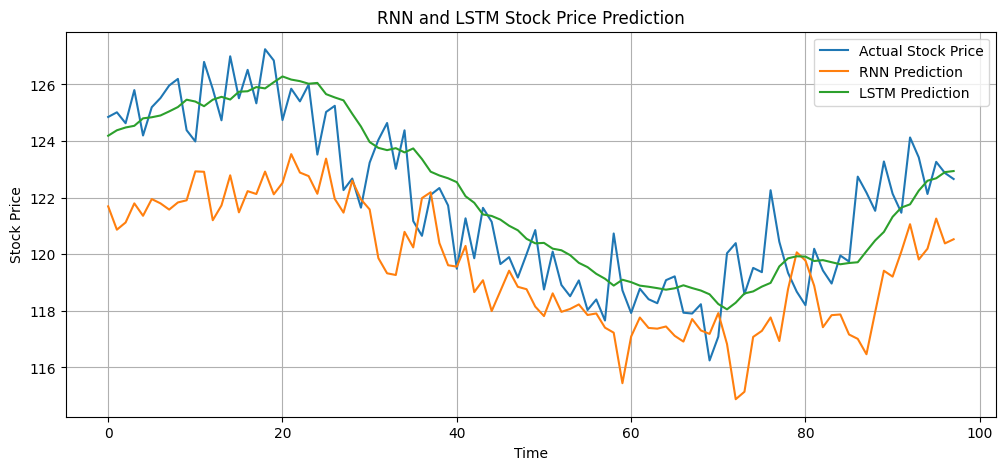

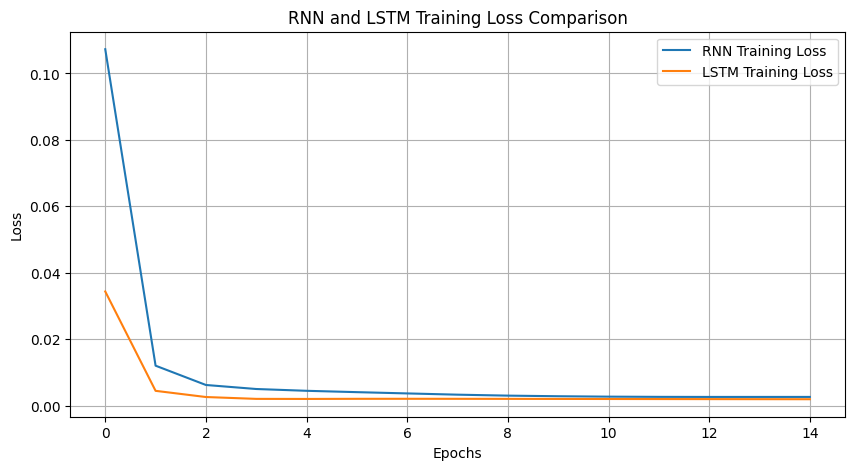

Best Model: LSTM


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)
tf.random.set_seed(42)

# Generate stock price dataset
time = np.arange(0, 500)
stock_prices = 100 + 0.05 * time + 5 * np.sin(0.05 * time) + np.random.normal(0, 1, 500)

# Normalize the data
scaler = MinMaxScaler()
scaled_prices = scaler.fit_transform(stock_prices.reshape(-1, 1))

# Create input sequences
X, Y = [], []
sequence_length = 10

for i in range(len(scaled_prices) - sequence_length):
    X.append(scaled_prices[i:i + sequence_length])
    Y.append(scaled_prices[i + sequence_length])

X = np.array(X)
Y = np.array(Y)

# Split dataset
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = Y[:split], Y[split:]

# Build Simple RNN model
rnn_model = Sequential([
    SimpleRNN(50, activation='tanh', input_shape=(10, 1)),
    Dense(1)
])

rnn_model.compile(optimizer='adam', loss='mse')

# Train RNN
rnn_history = rnn_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

# Build LSTM model
lstm_model = Sequential([
    LSTM(50, activation='tanh', input_shape=(10, 1)),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')

# Train LSTM
lstm_history = lstm_model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

# Make predictions
rnn_predictions = rnn_model.predict(X_test)
lstm_predictions = lstm_model.predict(X_test)

# Convert predictions to original scale
actual = scaler.inverse_transform(y_test)
rnn_predictions = scaler.inverse_transform(rnn_predictions)
lstm_predictions = scaler.inverse_transform(lstm_predictions)

# Calculate errors
rnn_mse = mean_squared_error(actual, rnn_predictions)
lstm_mse = mean_squared_error(actual, lstm_predictions)

rnn_mae = mean_absolute_error(actual, rnn_predictions)
lstm_mae = mean_absolute_error(actual, lstm_predictions)

print("RNN MSE:", rnn_mse)
print("LSTM MSE:", lstm_mse)
print("RNN MAE:", rnn_mae)
print("LSTM MAE:", lstm_mae)

# Compare actual and predicted stock prices
plt.figure(figsize=(12, 5))
plt.plot(actual, label='Actual Stock Price')
plt.plot(rnn_predictions, label='RNN Prediction')
plt.plot(lstm_predictions, label='LSTM Prediction')
plt.title("RNN and LSTM Stock Price Prediction")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.grid()
plt.show()

# Compare training loss
plt.figure(figsize=(10, 5))
plt.plot(rnn_history.history['loss'], label='RNN Training Loss')
plt.plot(lstm_history.history['loss'], label='LSTM Training Loss')
plt.title("RNN and LSTM Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

print("Best Model:", "LSTM" if lstm_mse < rnn_mse else "RNN")

17

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Test Loss Without Gradient Clipping: 0.0014113489305600524
Test Loss With Gradient Clipping: 0.0036811630707234144
Without Clipping Gradient Norm: 5.994631
With Clipping Gradient Norm: 6.0137506


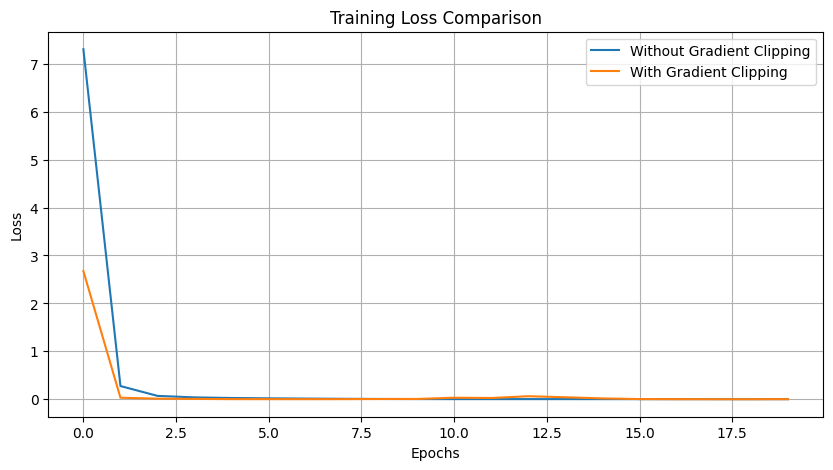

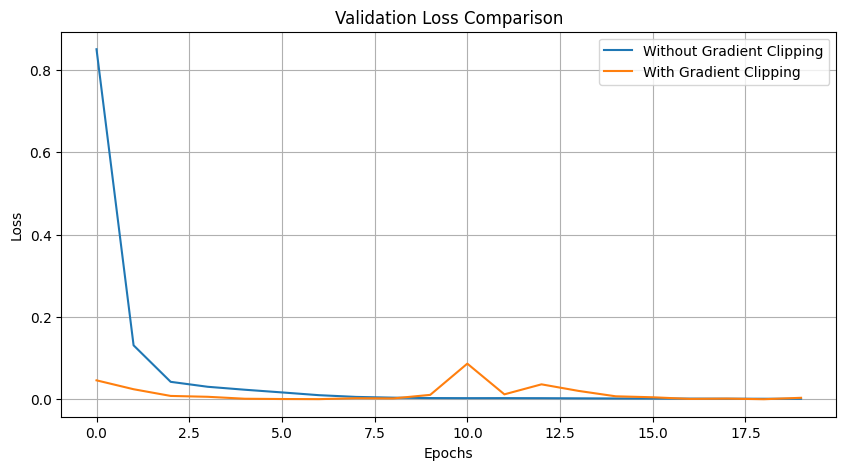

1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step


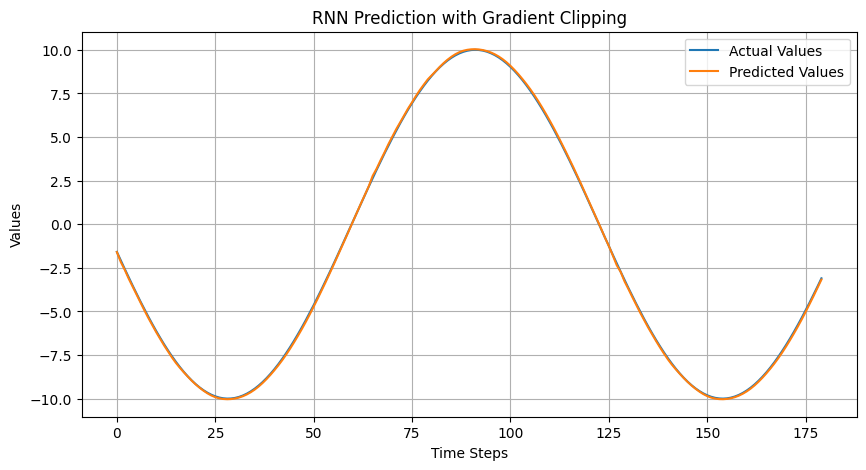

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

np.random.seed(42)
tf.random.set_seed(42)

# Generate sequential numerical dataset
data = np.sin(np.arange(1000) * 0.05) * 10

X, Y = [], []
sequence_length = 20

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    Y.append(data[i + sequence_length])

X = np.array(X).reshape(-1, sequence_length, 1)
Y = np.array(Y)

X_train, X_test = X[:800], X[800:]
y_train, y_test = Y[:800], Y[800:]

# Function to create RNN model
def create_model(clip_value=None):
    model = Sequential([
        SimpleRNN(32, activation='tanh',
                  input_shape=(sequence_length, 1)),
        Dense(1)
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=0.01,
        clipnorm=clip_value
    )

    model.compile(optimizer=optimizer, loss='mse')
    return model

# Model without gradient clipping
model_without = create_model()

history_without = model_without.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# Model with gradient clipping
model_with = create_model(clip_value=1.0)

history_with = model_with.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# Calculate test losses
loss_without = model_without.evaluate(X_test, y_test, verbose=0)
loss_with = model_with.evaluate(X_test, y_test, verbose=0)

print("Test Loss Without Gradient Clipping:", loss_without)
print("Test Loss With Gradient Clipping:", loss_with)

# Observe gradient values using GradientTape
sample_x = tf.convert_to_tensor(X_train[:32], dtype=tf.float32)
sample_y = tf.convert_to_tensor(y_train[:32], dtype=tf.float32)

for model, name in [
    (model_without, "Without Clipping"),
    (model_with, "With Clipping")
]:
    with tf.GradientTape() as tape:
        predictions = model(sample_x, training=True)
        loss = tf.reduce_mean(tf.square(sample_y - predictions))

    gradients = tape.gradient(loss, model.trainable_variables)
    gradient_norm = tf.linalg.global_norm(gradients)

    print(name, "Gradient Norm:", gradient_norm.numpy())

# Compare training loss
plt.figure(figsize=(10, 5))
plt.plot(history_without.history['loss'],
         label='Without Gradient Clipping')
plt.plot(history_with.history['loss'],
         label='With Gradient Clipping')
plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Compare validation loss
plt.figure(figsize=(10, 5))
plt.plot(history_without.history['val_loss'],
         label='Without Gradient Clipping')
plt.plot(history_with.history['val_loss'],
         label='With Gradient Clipping')
plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Predict using clipped model
predictions = model_with.predict(X_test)

plt.figure(figsize=(10, 5))
plt.plot(y_test, label='Actual Values')
plt.plot(predictions, label='Predicted Values')
plt.title("RNN Prediction with Gradient Clipping")
plt.xlabel("Time Steps")
plt.ylabel("Values")
plt.legend()
plt.grid()
plt.show()

18


Training: RNN Units: 16 Learning Rate: 0.001 Batch Size: 16


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training: RNN Units: 32 Learning Rate: 0.001 Batch Size: 32

Training: RNN Units: 64 Learning Rate: 0.01 Batch Size: 16

Training: LSTM Units: 16 Learning Rate: 0.001 Batch Size: 16

Training: LSTM Units: 32 Learning Rate: 0.001 Batch Size: 32

Training: LSTM Units: 64 Learning Rate: 0.01 Batch Size: 16

Training: GRU Units: 16 Learning Rate: 0.001 Batch Size: 16

Training: GRU Units: 32 Learning Rate: 0.001 Batch Size: 32

Training: GRU Units: 64 Learning Rate: 0.01 Batch Size: 16

Model Performance Comparison
RNN Test Loss: 0.0012375380611047149
LSTM Test Loss: 0.0011346478713676333
GRU Test Loss: 0.0013433530693873763

Best Model: LSTM


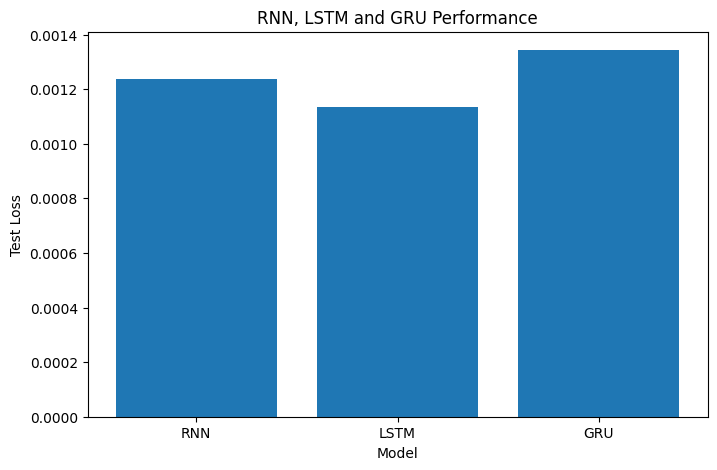

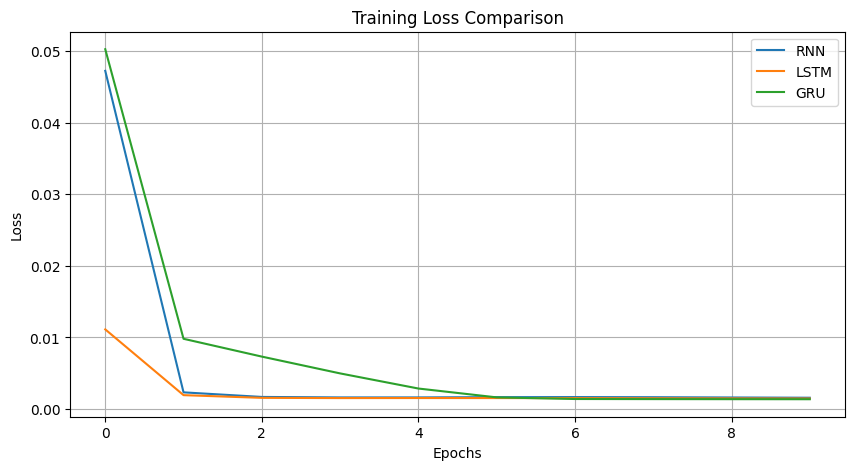

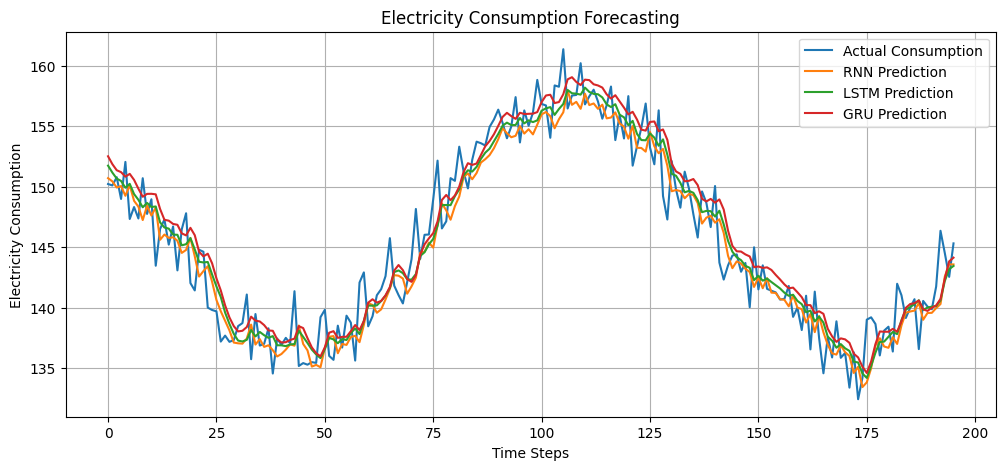

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

# Generate electricity consumption dataset
time = np.arange(1000)
electricity = (
    100 + 0.05 * time
    + 10 * np.sin(0.05 * time)
    + 5 * np.sin(0.01 * time)
    + np.random.normal(0, 2, 1000)
)

# Normalize dataset
scaler = MinMaxScaler()
data = scaler.fit_transform(electricity.reshape(-1, 1))

# Create sequences
X, Y = [], []
sequence_length = 20

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    Y.append(data[i + sequence_length])

X = np.array(X)
Y = np.array(Y)

# Split dataset
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = Y[:split], Y[split:]

# Function to build models
def build_model(model_type, units, learning_rate):
    model = Sequential()

    if model_type == "RNN":
        model.add(SimpleRNN(units, activation='tanh',
                            input_shape=(sequence_length, 1)))
    elif model_type == "LSTM":
        model.add(LSTM(units, input_shape=(sequence_length, 1)))
    else:
        model.add(GRU(units, input_shape=(sequence_length, 1)))

    model.add(Dense(1))

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(optimizer=optimizer, loss='mse')
    return model

# Hyperparameter configurations
configurations = [
    (16, 0.001, 16),
    (32, 0.001, 32),
    (64, 0.01, 16)
]

results = {}
histories = {}
predictions = {}

# Train RNN, LSTM and GRU models
for model_type in ["RNN", "LSTM", "GRU"]:
    best_loss = float('inf')

    for units, lr, batch in configurations:
        print("\nTraining:", model_type,
              "Units:", units,
              "Learning Rate:", lr,
              "Batch Size:", batch)

        model = build_model(model_type, units, lr)

        history = model.fit(
            X_train, y_train,
            epochs=10,
            batch_size=batch,
            validation_split=0.2,
            verbose=0
        )

        loss = model.evaluate(X_test, y_test, verbose=0)

        if loss < best_loss:
            best_loss = loss
            results[model_type] = loss
            histories[model_type] = history
            predictions[model_type] = model.predict(X_test, verbose=0)

# Display model performance
print("\nModel Performance Comparison")

for name, loss in results.items():
    print(name, "Test Loss:", loss)

best_model = min(results, key=results.get)
print("\nBest Model:", best_model)

# Plot model performance
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values())
plt.title("RNN, LSTM and GRU Performance")
plt.xlabel("Model")
plt.ylabel("Test Loss")
plt.show()

# Plot training loss
plt.figure(figsize=(10, 5))

for name, history in histories.items():
    plt.plot(history.history['loss'], label=name)

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# Plot actual and predicted electricity consumption
actual = scaler.inverse_transform(y_test)

plt.figure(figsize=(12, 5))
plt.plot(actual, label="Actual Consumption")

for name, prediction in predictions.items():
    predicted = scaler.inverse_transform(prediction)
    plt.plot(predicted, label=name + " Prediction")

plt.title("Electricity Consumption Forecasting")
plt.xlabel("Time Steps")
plt.ylabel("Electricity Consumption")
plt.legend()
plt.grid()
plt.show()

19

Original Student Dataset:
   Attendance  Internal_Marks  Assignment_Scores  Exam_Marks
0          88             100                 44          62
1          78              38                 91          97
2          64              30                 73          62
3          92              37                 45          43
4          57              92                 61          50

Eigenvalues:
[1.20869282 1.05250393 0.95325449 0.8259528 ]

Explained Variance Ratio:
[0.29915147 0.26049472 0.23593049 0.20442332]

Cumulative Explained Variance:
[0.29915147 0.5596462  0.79557668 1.        ]

Reduced Dataset:
   Principal Component 1  Principal Component 2
0              -2.259699               0.124510
1               2.017594               0.990951
2               1.066667               0.048843
3              -1.183047               1.414479
4              -1.025050              -1.764634


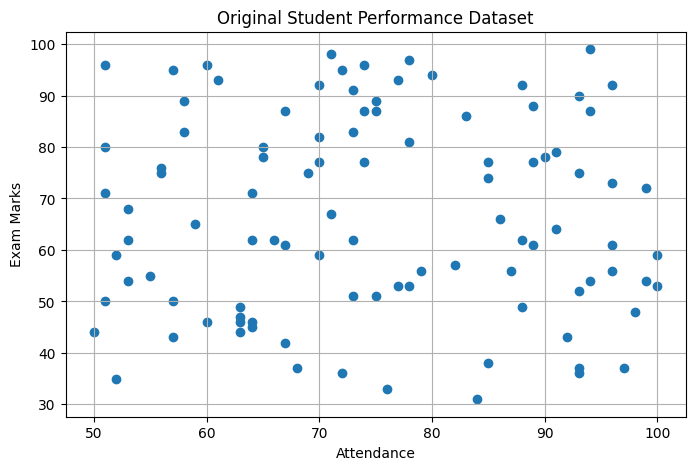

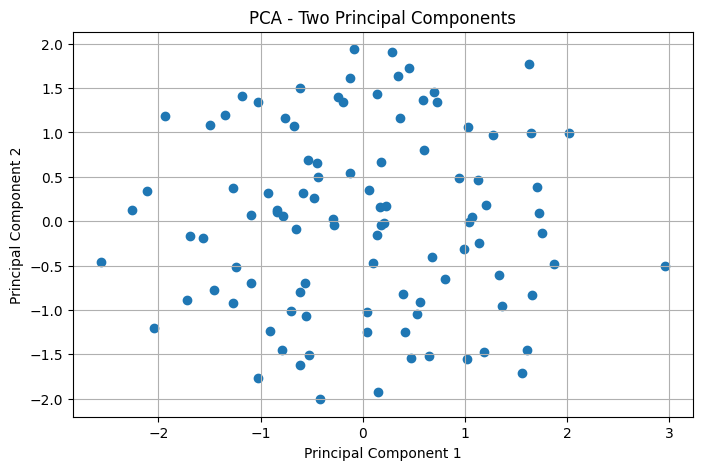

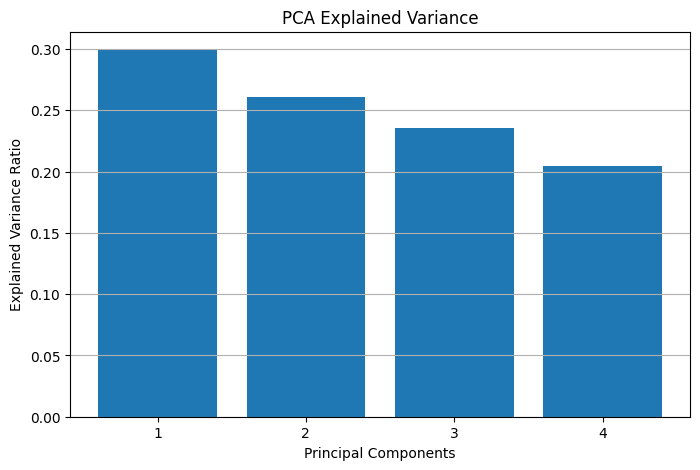


Components Required to Retain 95% Information: 4


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Generate student performance dataset
np.random.seed(42)

data = {
    'Attendance': np.random.randint(50, 101, 100),
    'Internal_Marks': np.random.randint(30, 101, 100),
    'Assignment_Scores': np.random.randint(40, 101, 100),
    'Exam_Marks': np.random.randint(30, 101, 100)
}

df = pd.DataFrame(data)

print("Original Student Dataset:")
print(df.head())

# Standardize the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Apply PCA
pca = PCA()
pca_result = pca.fit_transform(scaled_data)

# Calculate eigenvalues
eigenvalues = pca.explained_variance_

print("\nEigenvalues:")
print(eigenvalues)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("\nExplained Variance Ratio:")
print(explained_variance)

print("\nCumulative Explained Variance:")
print(np.cumsum(explained_variance))

# Reduce dataset to two principal components
pca_2 = PCA(n_components=2)
reduced_data = pca_2.fit_transform(scaled_data)

reduced_df = pd.DataFrame(
    reduced_data,
    columns=['Principal Component 1', 'Principal Component 2']
)

print("\nReduced Dataset:")
print(reduced_df.head())

# Visualize original dataset
plt.figure(figsize=(8, 5))
plt.scatter(df['Attendance'], df['Exam_Marks'])
plt.title("Original Student Performance Dataset")
plt.xlabel("Attendance")
plt.ylabel("Exam Marks")
plt.grid()
plt.show()

# Visualize reduced dataset
plt.figure(figsize=(8, 5))
plt.scatter(reduced_data[:, 0], reduced_data[:, 1])
plt.title("PCA - Two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid()
plt.show()

# Explained variance graph
plt.figure(figsize=(8, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance
)
plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(axis='y')
plt.show()

# Find components required for 95% variance
cumulative_variance = np.cumsum(explained_variance)
required_components = np.argmax(cumulative_variance >= 0.95) + 1

print("\nComponents Required to Retain 95% Information:",
      required_components)

20

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset Shape: (400, 4096)
Image Shape: (400, 64, 64)

Latent Dimensions: 10
Reconstruction Error: 0.0066913557

Latent Dimensions: 50
Reconstruction Error: 0.0024708621

Latent Dimensions: 100
Reconstruction Error: 0.0012700894


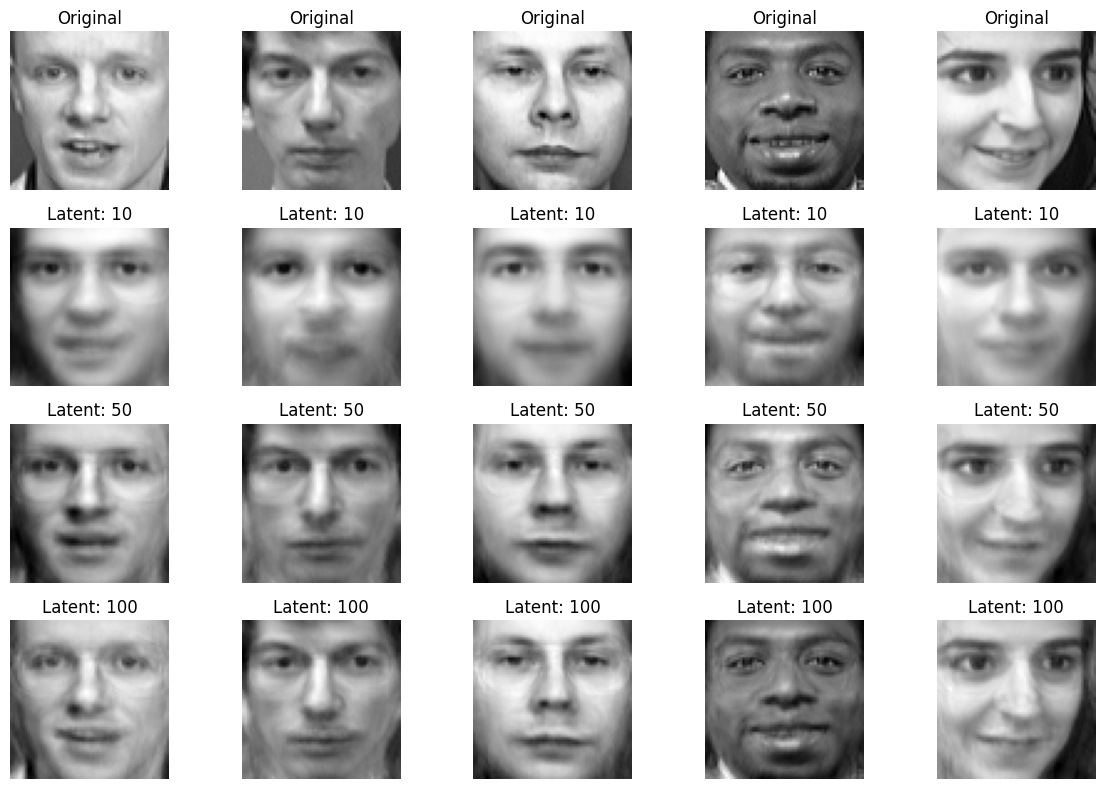

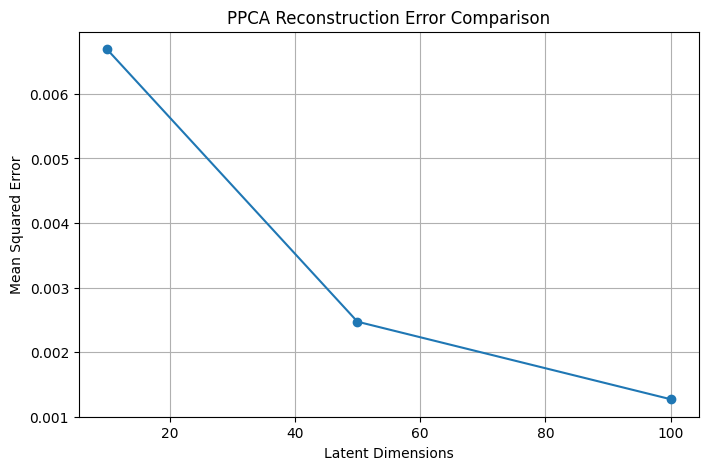


Best Latent Dimension: 100
Minimum Reconstruction Error: 0.0012700894


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load face image dataset
faces = fetch_olivetti_faces(shuffle=True, random_state=42)

X = faces.data
images = faces.images

print("Dataset Shape:", X.shape)
print("Image Shape:", images.shape)

# Standardize the face image data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA as a probabilistic PCA approximation
latent_dimensions = [10, 50, 100]

reconstruction_errors = []
reconstructed_images = []

for n in latent_dimensions:
    pca = PCA(n_components=n, svd_solver='full')

    # Reduce dimensions
    X_reduced = pca.fit_transform(X_scaled)

    # Reconstruct images
    X_reconstructed = pca.inverse_transform(X_reduced)
    X_reconstructed = scaler.inverse_transform(X_reconstructed)

    # Calculate reconstruction error
    error = np.mean((X - X_reconstructed) ** 2)
    reconstruction_errors.append(error)

    reconstructed_images.append(
        X_reconstructed.reshape(-1, 64, 64)
    )

    print("\nLatent Dimensions:", n)
    print("Reconstruction Error:", error)

# Display original and reconstructed images
plt.figure(figsize=(12, 8))

for i in range(5):
    plt.subplot(4, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    for j in range(3):
        plt.subplot(4, 5, (j + 1) * 5 + i + 1)
        plt.imshow(reconstructed_images[j][i], cmap='gray')
        plt.title(f"Latent: {latent_dimensions[j]}")
        plt.axis('off')

plt.tight_layout()
plt.show()

# Compare reconstruction errors
plt.figure(figsize=(8, 5))
plt.plot(latent_dimensions, reconstruction_errors,
         marker='o')
plt.title("PPCA Reconstruction Error Comparison")
plt.xlabel("Latent Dimensions")
plt.ylabel("Mean Squared Error")
plt.grid()
plt.show()

# Print best latent dimension
best_index = np.argmin(reconstruction_errors)

print("\nBest Latent Dimension:", latent_dimensions[best_index])
print("Minimum Reconstruction Error:",
      reconstruction_errors[best_index])

21

Customer Satisfaction Dataset:
   Service_Quality  Product_Quality   Pricing  Delivery  Customer_Support
0         4.624468         4.531936  2.644265  3.140772          3.099133
1         3.612739         4.237736  3.297890  2.507869          3.326172
2         4.779033         4.786972  3.522084  3.223854          4.088802
3         5.625115         4.598979  3.343503  3.924546          4.462320
4         3.936708         2.905283  3.349415  2.693304          3.448561

Factor Loadings:
                  Factor 1  Factor 2
Service_Quality  -0.897695  0.078894
Product_Quality  -0.101264 -0.166250
Pricing           0.134814  0.230090
Delivery         -0.731263  0.245858
Customer_Support -0.860486 -0.198827

Extracted Latent Factors:
   Factor 1  Factor 2
0 -0.436651  0.297854
1  0.208483 -0.451674
2 -1.075048 -0.318297
3 -1.952529  0.071872
4 -0.073956 -0.096808


<Figure size 900x500 with 0 Axes>

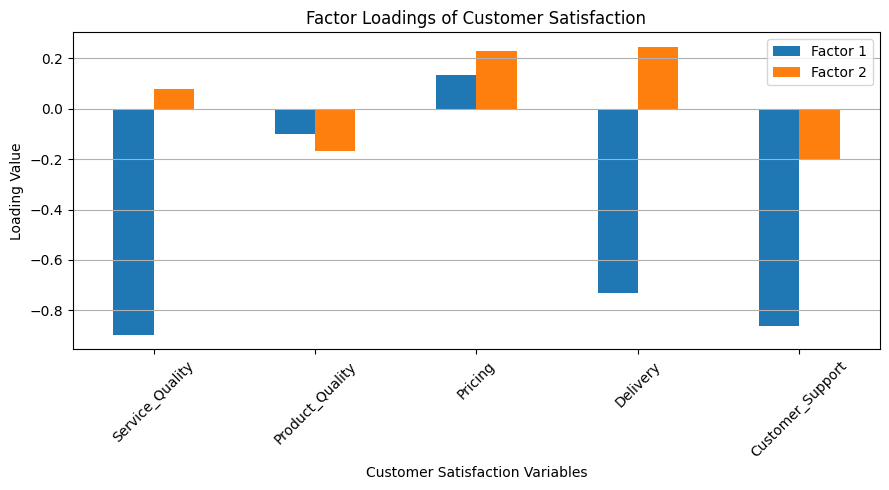

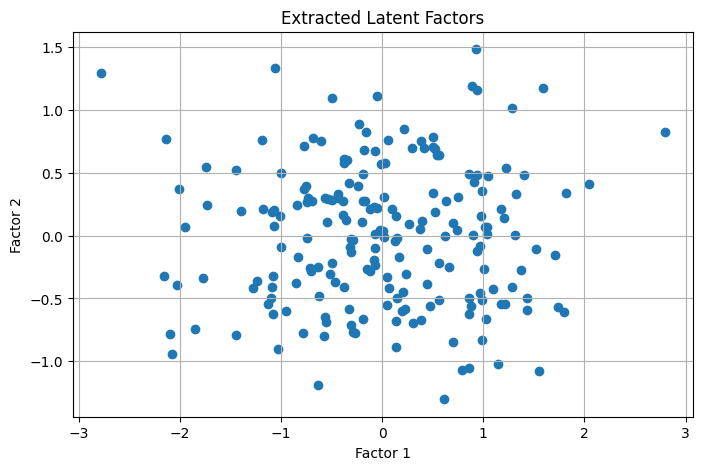


Factor Interpretation:

 Factor 1
Service_Quality    -0.897695
Customer_Support   -0.860486
Delivery           -0.731263
Pricing             0.134814
Product_Quality    -0.101264
Name: Factor 1, dtype: float64

 Factor 2
Delivery            0.245858
Pricing             0.230090
Customer_Support   -0.198827
Product_Quality    -0.166250
Service_Quality     0.078894
Name: Factor 2, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis
from sklearn.preprocessing import StandardScaler

# Generate customer satisfaction dataset
np.random.seed(42)

n = 200

service_quality = np.random.normal(4, 0.8, n)
product_quality = np.random.normal(4, 0.7, n)
pricing = np.random.normal(3.5, 0.8, n)

data = pd.DataFrame({
    'Service_Quality': service_quality + np.random.normal(0, 0.3, n),
    'Product_Quality': product_quality + np.random.normal(0, 0.3, n),
    'Pricing': pricing + np.random.normal(0, 0.3, n),
    'Delivery': service_quality * 0.7 + np.random.normal(0, 0.5, n),
    'Customer_Support': service_quality * 0.8 + np.random.normal(0, 0.4, n)
})

print("Customer Satisfaction Dataset:")
print(data.head())

# Standardize the dataset
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

# Apply Factor Analysis
fa = FactorAnalysis(n_components=2, random_state=42)
factor_values = fa.fit_transform(scaled_data)

# Display factor loadings
loadings = pd.DataFrame(
    fa.components_.T,
    index=data.columns,
    columns=['Factor 1', 'Factor 2']
)

print("\nFactor Loadings:")
print(loadings)

# Display latent factor values
factor_df = pd.DataFrame(
    factor_values,
    columns=['Factor 1', 'Factor 2']
)

print("\nExtracted Latent Factors:")
print(factor_df.head())

# Visualize factor loadings
plt.figure(figsize=(9, 5))
loadings.plot(kind='bar', figsize=(9, 5))
plt.title("Factor Loadings of Customer Satisfaction")
plt.xlabel("Customer Satisfaction Variables")
plt.ylabel("Loading Value")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Visualize extracted factors
plt.figure(figsize=(8, 5))
plt.scatter(factor_values[:, 0], factor_values[:, 1])
plt.title("Extracted Latent Factors")
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.grid()
plt.show()

# Interpret factor loadings
print("\nFactor Interpretation:")

for factor in loadings.columns:
    print("\n", factor)
    print(loadings[factor].sort_values(
        key=abs, ascending=False
    ))

22

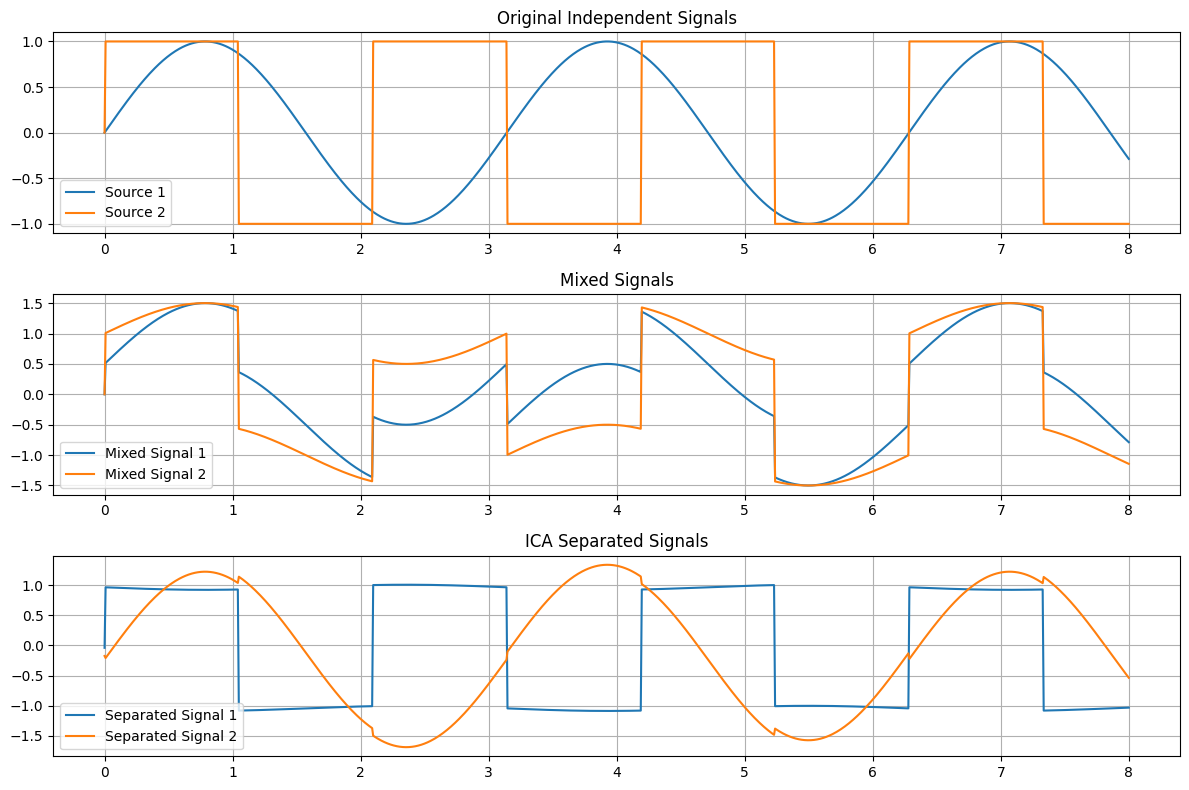

Original Signal Shape: (1000, 2)
Mixed Signal Shape: (1000, 2)
Separated Signal Shape: (1000, 2)

ICA Mixing Matrix:
[[0.5383259  0.70338152]
 [1.01770952 0.37351891]]

ICA successfully separated the mixed signals.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import FastICA

# Generate independent source signals
np.random.seed(42)

samples = 1000
time = np.linspace(0, 8, samples)

# Source 1: Sine wave
source1 = np.sin(2 * time)

# Source 2: Square wave
source2 = np.sign(np.sin(3 * time))

# Combine independent signals
S = np.c_[source1, source2]

# Mix the signals
mixing_matrix = np.array([
    [1, 0.5],
    [0.5, 1]
])

mixed_signals = np.dot(S, mixing_matrix.T)

# Apply Independent Component Analysis
ica = FastICA(n_components=2, random_state=42)
separated_signals = ica.fit_transform(mixed_signals)

# Display original signals
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(time, source1, label='Source 1')
plt.plot(time, source2, label='Source 2')
plt.title("Original Independent Signals")
plt.legend()
plt.grid()

# Display mixed signals
plt.subplot(3, 1, 2)
plt.plot(time, mixed_signals[:, 0], label='Mixed Signal 1')
plt.plot(time, mixed_signals[:, 1], label='Mixed Signal 2')
plt.title("Mixed Signals")
plt.legend()
plt.grid()

# Display separated signals
plt.subplot(3, 1, 3)
plt.plot(time, separated_signals[:, 0], label='Separated Signal 1')
plt.plot(time, separated_signals[:, 1], label='Separated Signal 2')
plt.title("ICA Separated Signals")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# Compare original and separated signals
print("Original Signal Shape:", S.shape)
print("Mixed Signal Shape:", mixed_signals.shape)
print("Separated Signal Shape:", separated_signals.shape)

print("\nICA Mixing Matrix:")
print(ica.mixing_)

print("\nICA successfully separated the mixed signals.")

23

Bayesian Network Probabilities
Cloudy: 0 Humidity: 0 Probability of Rain: 0.1
Cloudy: 0 Humidity: 1 Probability of Rain: 0.3
Cloudy: 1 Humidity: 0 Probability of Rain: 0.6
Cloudy: 1 Humidity: 1 Probability of Rain: 0.9

Overall Probability of Rainfall: 0.5
Probability of Carrying Umbrella: 0.5


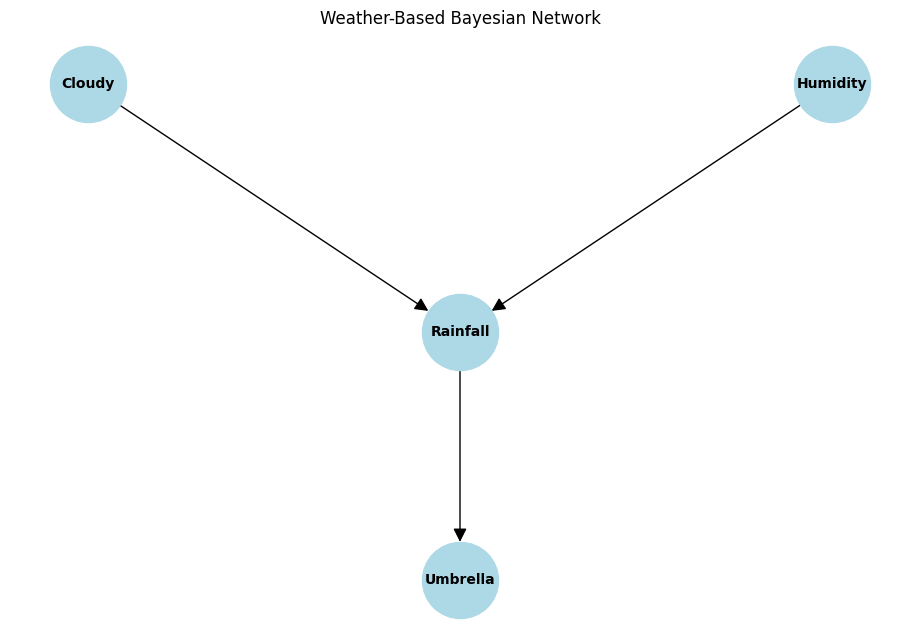

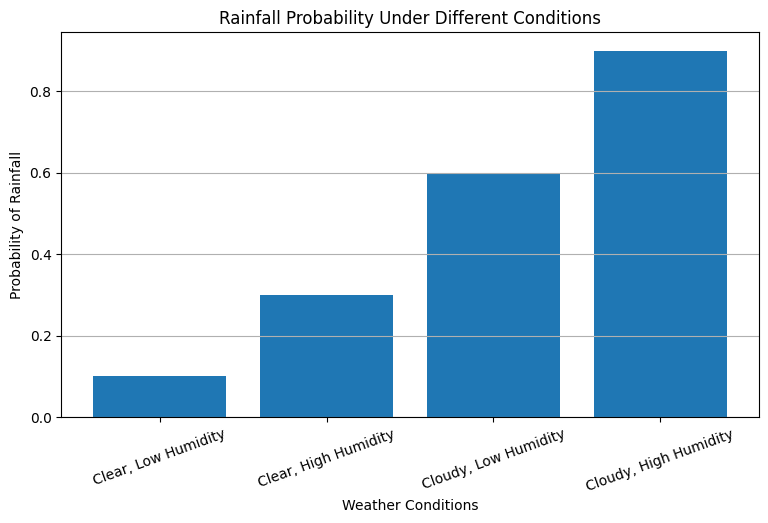

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Define Bayesian Network structure
G = nx.DiGraph()

G.add_edges_from([
    ("Cloudy", "Rainfall"),
    ("Humidity", "Rainfall"),
    ("Rainfall", "Umbrella")
])

# Define conditional probabilities
P_cloudy = {0: 0.5, 1: 0.5}
P_humidity = {0: 0.4, 1: 0.6}

# P(Rainfall = Yes | Cloudy, Humidity)
P_rain = {
    (0, 0): 0.1,
    (0, 1): 0.3,
    (1, 0): 0.6,
    (1, 1): 0.9
}

# P(Umbrella = Yes | Rainfall)
P_umbrella = {
    0: 0.1,
    1: 0.9
}

# Calculate probability of rainfall
def probability_rainfall(cloudy, humidity):
    return P_rain[(cloudy, humidity)]

print("Bayesian Network Probabilities")

for cloudy in [0, 1]:
    for humidity in [0, 1]:
        probability = probability_rainfall(cloudy, humidity)
        print(
            "Cloudy:", cloudy,
            "Humidity:", humidity,
            "Probability of Rain:", probability
        )

# Calculate overall probability of rainfall
total_probability = 0

for cloudy in [0, 1]:
    for humidity in [0, 1]:
        p = (
            P_cloudy[cloudy]
            * P_humidity[humidity]
            * P_rain[(cloudy, humidity)]
        )
        total_probability += p

print("\nOverall Probability of Rainfall:",
      total_probability)

# Calculate probability of carrying umbrella
p_umbrella = (
    (1 - total_probability) * P_umbrella[0]
    + total_probability * P_umbrella[1]
)

print("Probability of Carrying Umbrella:", p_umbrella)

# Visualize Bayesian Network
plt.figure(figsize=(9, 6))

pos = {
    "Cloudy": (0, 2),
    "Humidity": (2, 2),
    "Rainfall": (1, 1),
    "Umbrella": (1, 0)
}

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_size=10,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Weather-Based Bayesian Network")
plt.show()

# Visualize rainfall probabilities
labels = [
    "Clear, Low Humidity",
    "Clear, High Humidity",
    "Cloudy, Low Humidity",
    "Cloudy, High Humidity"
]

values = [
    P_rain[(0, 0)],
    P_rain[(0, 1)],
    P_rain[(1, 0)],
    P_rain[(1, 1)]
]

plt.figure(figsize=(9, 5))
plt.bar(labels, values)
plt.title("Rainfall Probability Under Different Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Probability of Rainfall")
plt.xticks(rotation=20)
plt.grid(axis='y')
plt.show()

24

Generated Medical Dataset:
   Disease  Fever  Cough  Fatigue
0        0      0      0        0
1        1      1      1        1
2        0      1      1        0
3        0      0      0        0
4        0      1      0        0

Disease Probability Under Different Symptoms:
Fever: 1 Cough: 0 Fatigue: 0 Disease Probability: 0.0233
Fever: 1 Cough: 1 Fatigue: 0 Disease Probability: 0.1148
Fever: 1 Cough: 1 Fatigue: 1 Disease Probability: 0.8235
Fever: 0 Cough: 0 Fatigue: 0 Disease Probability: 0.0015


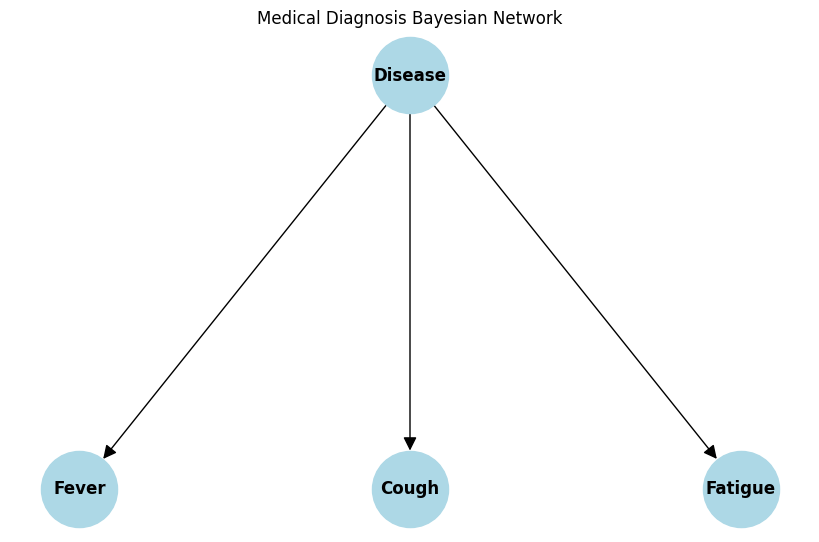

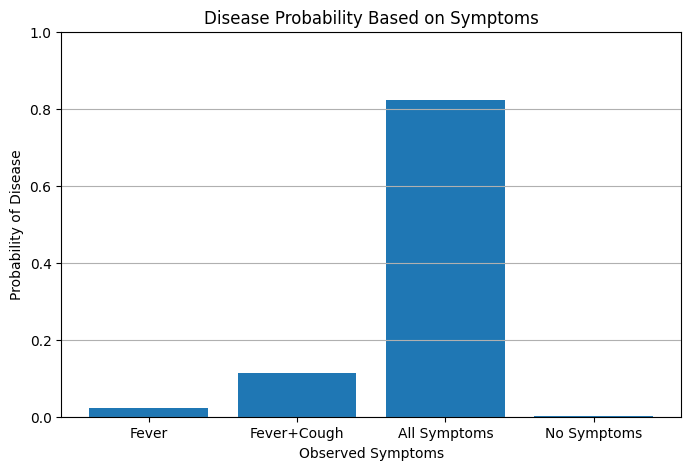


Symptom Frequency:
Fever      0.264
Cough      0.349
Fatigue    0.269
dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

np.random.seed(42)

# Define prior probability
P_disease = 0.1

# Conditional probabilities of symptoms
P_fever = {1: 0.8, 0: 0.2}
P_cough = {1: 0.7, 0: 0.3}
P_fatigue = {1: 0.9, 0: 0.2}

# Generate samples
n = 1000

disease = np.random.binomial(1, P_disease, n)
fever = np.array([
    np.random.binomial(1, P_fever[d]) for d in disease
])
cough = np.array([
    np.random.binomial(1, P_cough[d]) for d in disease
])
fatigue = np.array([
    np.random.binomial(1, P_fatigue[d]) for d in disease
])

# Create dataset
data = pd.DataFrame({
    'Disease': disease,
    'Fever': fever,
    'Cough': cough,
    'Fatigue': fatigue
})

print("Generated Medical Dataset:")
print(data.head())

# Calculate probability using Bayes' theorem
def calculate_probability(f, c, ft):
    prior = P_disease
    likelihood = (
        P_fever[1] if f else 1 - P_fever[1]
    ) * (
        P_cough[1] if c else 1 - P_cough[1]
    ) * (
        P_fatigue[1] if ft else 1 - P_fatigue[1]
    )

    likelihood_no_disease = (
        (0.2 if f else 0.8)
        * (0.3 if c else 0.7)
        * (0.2 if ft else 0.8)
    )

    numerator = prior * likelihood
    denominator = (
        numerator + (1 - prior) * likelihood_no_disease
    )

    return numerator / denominator

# Probabilistic inference
conditions = [
    (1, 0, 0),
    (1, 1, 0),
    (1, 1, 1),
    (0, 0, 0)
]

print("\nDisease Probability Under Different Symptoms:")

for f, c, ft in conditions:
    probability = calculate_probability(f, c, ft)
    print(
        "Fever:", f,
        "Cough:", c,
        "Fatigue:", ft,
        "Disease Probability:", round(probability, 4)
    )

# Compare probabilities
probabilities = [
    calculate_probability(f, c, ft)
    for f, c, ft in conditions
]

labels = [
    "Fever",
    "Fever+Cough",
    "All Symptoms",
    "No Symptoms"
]

# Construct graphical model
G = nx.DiGraph()
G.add_edges_from([
    ("Disease", "Fever"),
    ("Disease", "Cough"),
    ("Disease", "Fatigue")
])

plt.figure(figsize=(8, 5))
pos = {
    "Disease": (1, 2),
    "Fever": (0, 0),
    "Cough": (1, 0),
    "Fatigue": (2, 0)
}

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Medical Diagnosis Bayesian Network")
plt.show()

# Visualize inference results
plt.figure(figsize=(8, 5))
plt.bar(labels, probabilities)
plt.title("Disease Probability Based on Symptoms")
plt.xlabel("Observed Symptoms")
plt.ylabel("Probability of Disease")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

# Display symptom distribution
print("\nSymptom Frequency:")
print(data[['Fever', 'Cough', 'Fatigue']].mean())

25

Original User-Movie Dataset:
[[1 1 0 0 1]
 [1 0 0 1 1]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [1 0 1 0 1]
 [0 0 1 1 0]]

Reconstructed User-Movie Dataset:
[[1. 0. 0. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 0.]
 [0. 1. 1. 1. 0.]
 [1. 0. 0. 1. 1.]
 [0. 0. 1. 0. 0.]]

Reconstruction Error: 0.11074611278832669

Energy of First User Configuration:
-5.922400059335397

Hidden Layer Probabilities:
[[1.54152555e-02 5.60035488e-04 9.41166025e-01]
 [1.40243850e-02 6.26863091e-04 9.39161087e-01]
 [9.02250472e-01 9.88327241e-01 2.50980278e-01]
 [9.25025555e-01 9.96082953e-01 1.97651547e-01]
 [6.36676362e-02 5.72388116e-03 9.08772432e-01]
 [8.93453436e-01 9.89559329e-01 2.44339490e-01]]


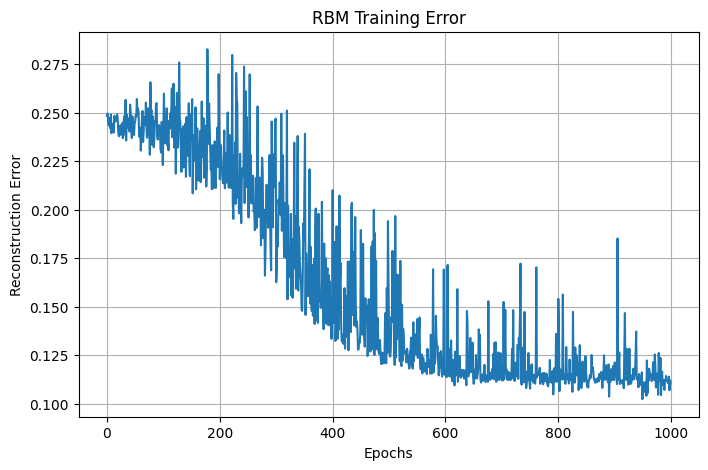

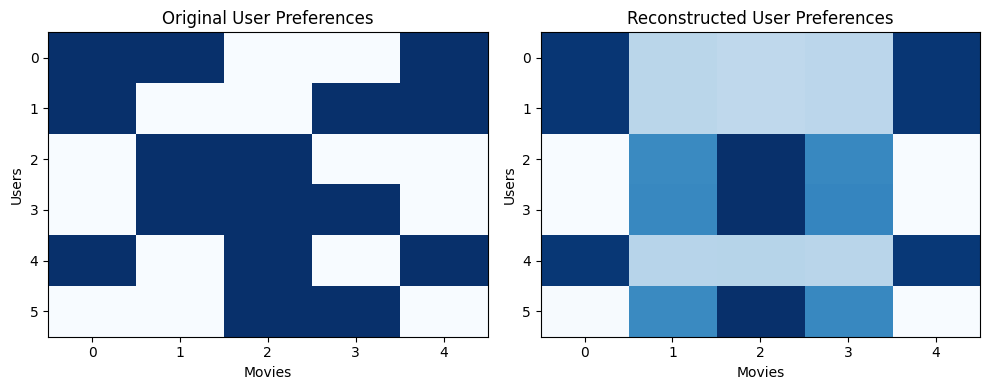

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Sample user-movie interaction dataset
ratings = np.array([
    [1, 1, 0, 0, 1],
    [1, 0, 0, 1, 1],
    [0, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 0, 1, 0, 1],
    [0, 0, 1, 1, 0]
])

print("Original User-Movie Dataset:")
print(ratings)

# RBM parameters
num_visible = ratings.shape[1]
num_hidden = 3
learning_rate = 0.1
epochs = 1000

W = np.random.normal(0, 0.1, (num_visible, num_hidden))
visible_bias = np.zeros(num_visible)
hidden_bias = np.zeros(num_hidden)

# Sigmoid activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

# Calculate hidden probabilities
def sample_hidden(v):
    probability = sigmoid(np.dot(v, W) + hidden_bias)
    sample = (np.random.rand(*probability.shape) < probability).astype(float)
    return probability, sample

# Calculate visible probabilities
def sample_visible(h):
    probability = sigmoid(np.dot(h, W.T) + visible_bias)
    sample = (np.random.rand(*probability.shape) < probability).astype(float)
    return probability, sample

# Calculate energy of a configuration
def calculate_energy(v, h):
    return -(
        np.dot(v, visible_bias)
        + np.dot(h, hidden_bias)
        + np.sum(np.dot(v, W) * h)
    )

# Train RBM using Contrastive Divergence
errors = []

for epoch in range(epochs):
    positive_hidden_prob, positive_hidden = sample_hidden(ratings)

    negative_visible_prob, negative_visible = sample_visible(
        positive_hidden
    )

    negative_hidden_prob, negative_hidden = sample_hidden(
        negative_visible
    )

    W += learning_rate * (
        np.dot(ratings.T, positive_hidden_prob)
        - np.dot(negative_visible.T, negative_hidden_prob)
    ) / len(ratings)

    visible_bias += learning_rate * np.mean(
        ratings - negative_visible, axis=0
    )

    hidden_bias += learning_rate * np.mean(
        positive_hidden_prob - negative_hidden_prob, axis=0
    )

    error = np.mean((ratings - negative_visible_prob) ** 2)
    errors.append(error)

# Reconstruct input patterns
hidden_prob, hidden_sample = sample_hidden(ratings)
reconstructed_prob, reconstructed_data = sample_visible(hidden_prob)

print("\nReconstructed User-Movie Dataset:")
print(reconstructed_data)

# Calculate reconstruction error
reconstruction_error = np.mean(
    (ratings - reconstructed_prob) ** 2
)

print("\nReconstruction Error:", reconstruction_error)

# Calculate energy
print("\nEnergy of First User Configuration:")
print(calculate_energy(ratings[0], hidden_sample[0]))

# Display hidden preferences
print("\nHidden Layer Probabilities:")
print(hidden_prob)

# Plot reconstruction error
plt.figure(figsize=(8, 5))
plt.plot(errors)
plt.title("RBM Training Error")
plt.xlabel("Epochs")
plt.ylabel("Reconstruction Error")
plt.grid()
plt.show()

# Compare original and reconstructed data
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(ratings, cmap='Blues', aspect='auto')
plt.title("Original User Preferences")
plt.xlabel("Movies")
plt.ylabel("Users")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_prob, cmap='Blues', aspect='auto')
plt.title("Reconstructed User Preferences")
plt.xlabel("Movies")
plt.ylabel("Users")

plt.tight_layout()
plt.show()

26

Original User Preference Dataset:
[[1. 1. 0. 0. 1.]
 [1. 0. 0. 1. 1.]
 [0. 1. 1. 0. 0.]
 [0. 1. 1. 1. 0.]
 [1. 0. 1. 0. 1.]
 [0. 0. 1. 1. 0.]]

CD- 1 Final Reconstruction Error: 0.13820342971453106

CD- 3 Final Reconstruction Error: 0.30936689233660253

CD- 5 Final Reconstruction Error: 0.137640013054576


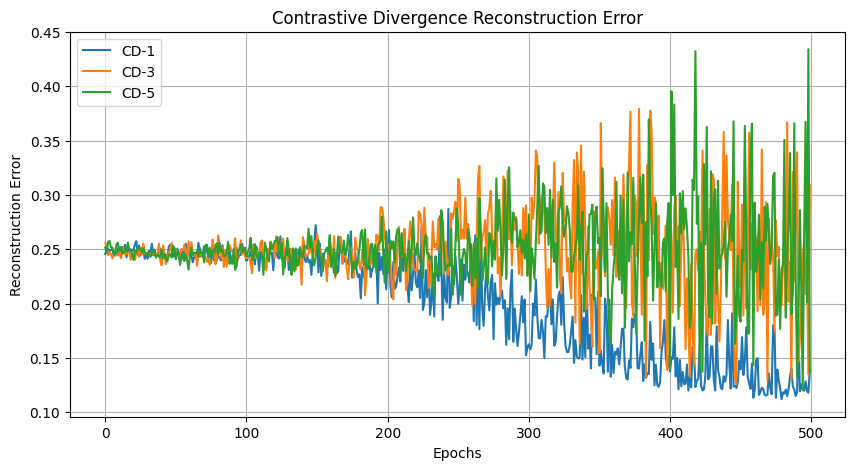


Original Dataset:
[[1. 1. 0. 0. 1.]
 [1. 0. 0. 1. 1.]
 [0. 1. 1. 0. 0.]
 [0. 1. 1. 1. 0.]
 [1. 0. 1. 0. 1.]
 [0. 0. 1. 1. 0.]]

Reconstructed Dataset:
[[1 0 0 0 1]
 [1 0 0 0 1]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 0 0 0 1]
 [0 1 1 1 0]]

Reconstruction Probabilities:
[[0.91570831 0.28983316 0.31438067 0.35540529 0.92610721]
 [0.91570831 0.28983316 0.31438067 0.35540529 0.92610721]
 [0.04413132 0.68321763 0.96571369 0.69660351 0.04849693]
 [0.04413132 0.68321763 0.96571369 0.69660351 0.04849693]
 [0.91570831 0.28983316 0.31438067 0.35540529 0.92610721]
 [0.04413132 0.68321763 0.96571369 0.69660351 0.04849693]]


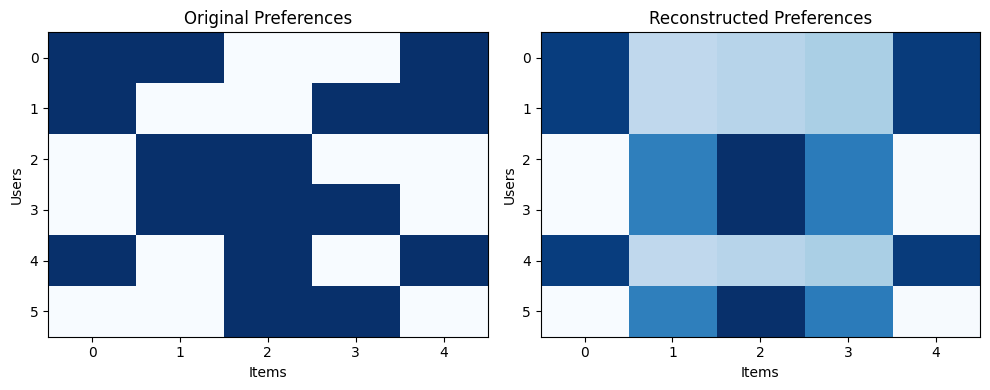

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Create binary user preference dataset
data = np.array([
    [1, 1, 0, 0, 1],
    [1, 0, 0, 1, 1],
    [0, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 0, 1, 0, 1],
    [0, 0, 1, 1, 0]
], dtype=float)

print("Original User Preference Dataset:")
print(data)

# Initialize RBM parameters
num_visible = data.shape[1]
num_hidden = 3
learning_rate = 0.1
epochs = 500

W = np.random.normal(0, 0.1, (num_visible, num_hidden))
vb = np.zeros(num_visible)
hb = np.zeros(num_hidden)

# Sigmoid function
def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))

# Visible-to-hidden sampling
def sample_hidden(v):
    probability = sigmoid(np.dot(v, W) + hb)
    sample = (np.random.rand(*probability.shape) < probability).astype(float)
    return probability, sample

# Hidden-to-visible sampling
def sample_visible(h):
    probability = sigmoid(np.dot(h, W.T) + vb)
    sample = (np.random.rand(*probability.shape) < probability).astype(float)
    return probability, sample

# Gibbs sampling
def gibbs_sampling(v, k):
    visible = v.copy()

    for _ in range(k):
        hidden_prob, hidden_sample = sample_hidden(visible)
        visible_prob, visible_sample = sample_visible(hidden_sample)

        visible = visible_sample

    return visible_prob, visible

# Contrastive Divergence training
def train_rbm(k):
    global W, vb, hb

    errors = []

    for epoch in range(epochs):
        positive_hidden_prob, positive_hidden = sample_hidden(data)

        negative_visible_prob, negative_visible = gibbs_sampling(
            data, k
        )

        negative_hidden_prob, negative_hidden = sample_hidden(
            negative_visible
        )

        W += learning_rate * (
            np.dot(data.T, positive_hidden_prob)
            - np.dot(negative_visible.T, negative_hidden_prob)
        ) / len(data)

        vb += learning_rate * np.mean(
            data - negative_visible, axis=0
        )

        hb += learning_rate * np.mean(
            positive_hidden_prob - negative_hidden_prob, axis=0
        )

        error = np.mean((data - negative_visible_prob) ** 2)
        errors.append(error)

    return errors

# Train RBM with different CD-k values
results = {}

for k in [1, 3, 5]:
    W = np.random.normal(0, 0.1, (num_visible, num_hidden))
    vb = np.zeros(num_visible)
    hb = np.zeros(num_hidden)

    errors = train_rbm(k)
    results[k] = errors

    print("\nCD-", k, "Final Reconstruction Error:", errors[-1])

# Visualize reconstruction errors
plt.figure(figsize=(10, 5))

for k, errors in results.items():
    plt.plot(errors, label=f"CD-{k}")

plt.title("Contrastive Divergence Reconstruction Error")
plt.xlabel("Epochs")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.grid()
plt.show()

# Perform final Gibbs sampling using the last trained model
hidden_prob, hidden_sample = sample_hidden(data)
reconstructed_prob, reconstructed_data = sample_visible(hidden_sample)

print("\nOriginal Dataset:")
print(data)

print("\nReconstructed Dataset:")
print((reconstructed_prob >= 0.5).astype(int))

print("\nReconstruction Probabilities:")
print(reconstructed_prob)

# Visualize original and reconstructed data
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(data, cmap='Blues', aspect='auto')
plt.title("Original Preferences")
plt.xlabel("Items")
plt.ylabel("Users")

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_prob, cmap='Blues', aspect='auto')
plt.title("Reconstructed Preferences")
plt.xlabel("Items")
plt.ylabel("Users")

plt.tight_layout()
plt.show()

27

Dataset Shape: (1797, 64)
Number of Classes: 10

First RBM Feature Shape: (1437, 128)
Second RBM Feature Shape: (1437, 64)

DBN Classification Accuracy: 0.625


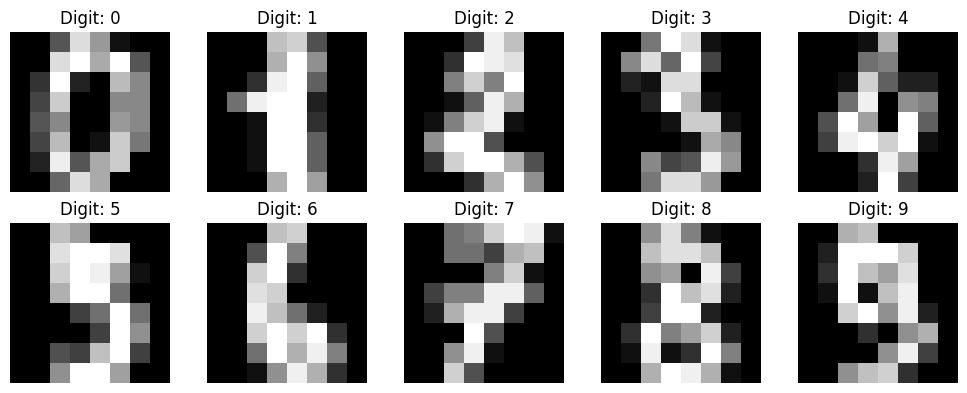

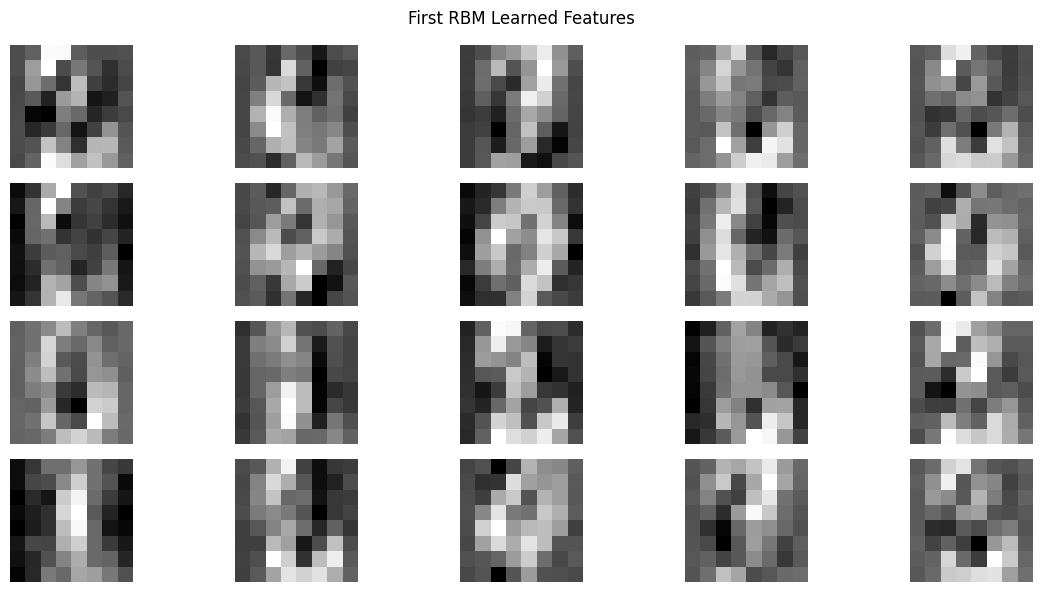

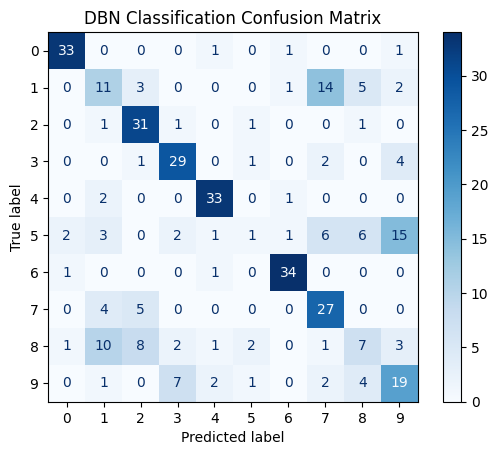


Deep Belief Network Feature Learning Completed


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import BernoulliRBM
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load handwritten digit dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset Shape:", X.shape)
print("Number of Classes:", len(np.unique(y)))

# Normalize the dataset
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# Convert pixel values into binary values
X = (X > 0.5).astype(float)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# First RBM layer
rbm1 = BernoulliRBM(
    n_components=128,
    learning_rate=0.01,
    n_iter=20,
    random_state=42
)

# Train first RBM
rbm1.fit(X_train)

# Extract first-level features
features1_train = rbm1.transform(X_train)
features1_test = rbm1.transform(X_test)

# Second RBM layer
rbm2 = BernoulliRBM(
    n_components=64,
    learning_rate=0.01,
    n_iter=20,
    random_state=42
)

# Train second RBM
rbm2.fit(features1_train)

# Extract hierarchical features
features2_train = rbm2.transform(features1_train)
features2_test = rbm2.transform(features1_test)

print("\nFirst RBM Feature Shape:", features1_train.shape)
print("Second RBM Feature Shape:", features2_train.shape)

# Train classifier using DBN features
classifier = LogisticRegression(max_iter=1000)
classifier.fit(features2_train, y_train)

# Predict handwritten digits
y_pred = classifier.predict(features2_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nDBN Classification Accuracy:", accuracy)

# Display sample handwritten digits
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title("Digit: " + str(y[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

# Visualize first-level learned features
plt.figure(figsize=(12, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(rbm1.components_[i].reshape(8, 8), cmap='gray')
    plt.axis('off')

plt.suptitle("First RBM Learned Features")
plt.tight_layout()
plt.show()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

display.plot(cmap='Blues')
plt.title("DBN Classification Confusion Matrix")
plt.show()

print("\nDeep Belief Network Feature Learning Completed")

28

Input Dataset Shape: (6, 64)

Reconstruction Error: 0.008649217467006445

Energy of First Image:
-153.67268652674616

Visible Layer Shape: (6, 64)
Hidden Layer 1 Shape: (6, 32)
Hidden Layer 2 Shape: (6, 16)


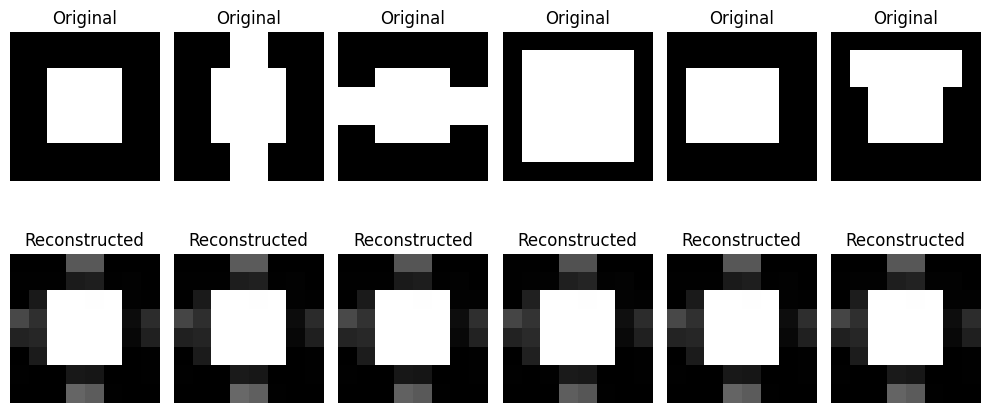

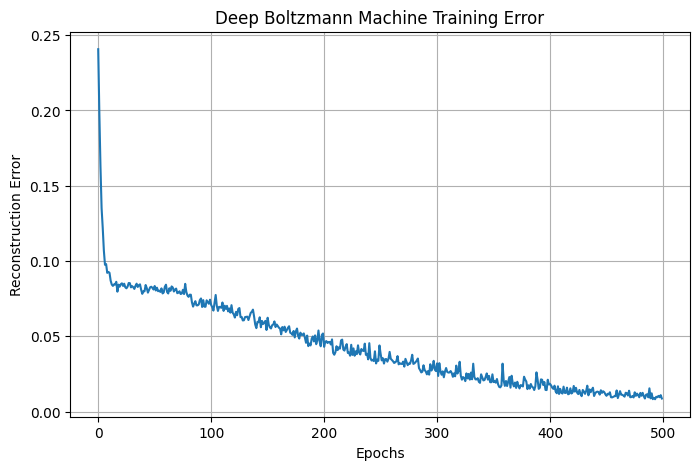

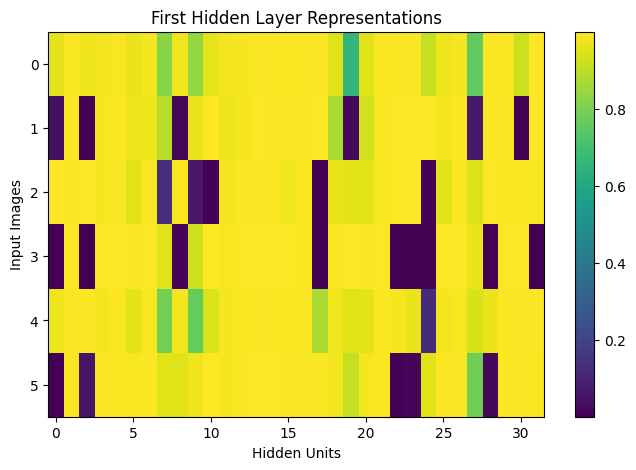

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Create sample image patterns (8x8)
images = np.zeros((6, 8, 8))

for i in range(6):
    images[i, 2:6, 2:6] = 1

images[1, :, 3:5] = 1
images[2, 3:5, :] = 1
images[3, 1:7, 1:7] = 1
images[4, 2:6, 1:3] = 1
images[5, 1:3, 1:7] = 1

# Flatten images into visible layer
X = images.reshape(6, 64)

print("Input Dataset Shape:", X.shape)

# Define visible and hidden layers
num_visible = 64
num_hidden1 = 32
num_hidden2 = 16

# Initialize weights and biases
W1 = np.random.normal(0, 0.1, (num_visible, num_hidden1))
W2 = np.random.normal(0, 0.1, (num_hidden1, num_hidden2))

vb = np.zeros(num_visible)
hb1 = np.zeros(num_hidden1)
hb2 = np.zeros(num_hidden2)

learning_rate = 0.05
epochs = 500

# Sigmoid function
def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))

# Sampling function
def sample(probability):
    return (np.random.rand(*probability.shape) < probability).astype(float)

# Calculate energy of the two-layer model
def calculate_energy(v, h1, h2):
    energy = -np.sum(v * vb)
    energy -= np.sum(h1 * hb1)
    energy -= np.sum(h2 * hb2)
    energy -= np.sum(np.dot(v, W1) * h1)
    energy -= np.sum(np.dot(h1, W2) * h2)
    return energy

# Training using simplified contrastive divergence
errors = []

for epoch in range(epochs):

    # Positive phase
    h1_prob = sigmoid(np.dot(X, W1) + hb1)
    h1_sample = sample(h1_prob)

    h2_prob = sigmoid(np.dot(h1_sample, W2) + hb2)
    h2_sample = sample(h2_prob)

    # Negative phase
    v_prob = sigmoid(np.dot(h1_sample, W1.T) + vb)
    v_sample = sample(v_prob)

    nh1_prob = sigmoid(np.dot(v_sample, W1) + hb1)
    nh1_sample = sample(nh1_prob)

    nh2_prob = sigmoid(np.dot(nh1_sample, W2) + hb2)

    # Update weights
    W1 += learning_rate * (
        np.dot(X.T, h1_prob) -
        np.dot(v_sample.T, nh1_prob)
    ) / len(X)

    W2 += learning_rate * (
        np.dot(h1_prob.T, h2_prob) -
        np.dot(nh1_prob.T, nh2_prob)
    ) / len(X)

    vb += learning_rate * np.mean(X - v_sample, axis=0)
    hb1 += learning_rate * np.mean(h1_prob - nh1_prob, axis=0)
    hb2 += learning_rate * np.mean(h2_prob - nh2_prob, axis=0)

    error = np.mean((X - v_prob) ** 2)
    errors.append(error)

# Reconstruct image patterns
h1_prob = sigmoid(np.dot(X, W1) + hb1)
h2_prob = sigmoid(np.dot(h1_prob, W2) + hb2)

reconstructed_h1 = sigmoid(np.dot(h2_prob, W2.T) + hb1)
reconstructed = sigmoid(np.dot(reconstructed_h1, W1.T) + vb)

print("\nReconstruction Error:", errors[-1])

print("\nEnergy of First Image:")
print(calculate_energy(X[0], h1_prob[0], h2_prob[0]))

print("\nVisible Layer Shape:", X.shape)
print("Hidden Layer 1 Shape:", h1_prob.shape)
print("Hidden Layer 2 Shape:", h2_prob.shape)

# Display original and reconstructed images
plt.figure(figsize=(10, 5))

for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 6, i + 7)
    plt.imshow(reconstructed[i].reshape(8, 8), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Plot training error
plt.figure(figsize=(8, 5))
plt.plot(errors)
plt.title("Deep Boltzmann Machine Training Error")
plt.xlabel("Epochs")
plt.ylabel("Reconstruction Error")
plt.grid()
plt.show()

# Visualize hidden layer representations
plt.figure(figsize=(8, 5))
plt.imshow(h1_prob, cmap='viridis', aspect='auto')
plt.title("First Hidden Layer Representations")
plt.xlabel("Hidden Units")
plt.ylabel("Input Images")
plt.colorbar()
plt.show()

29

Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)

Training VAE...
Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - kl_loss: 2.5701 - loss: 36.7690 - reconstruction_loss: 34.1989
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - kl_loss: 1.9773 - loss: 30.9481 - reconstruction_loss: 28.9708
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - kl_loss: 2.2237 - loss: 30.3430 - reconstruction_loss: 28.1192

Training GAN...
Epoch: 1 Generator Loss: 8.71692943572998 Discriminator Loss: 0.0012724037514999509
Epoch: 2 Generator Loss: 8.337337493896484 Discriminator Loss: 0.0028259616810828447
Epoch: 3 Generator Loss: 11.435765266418457 Discriminator Loss: 7.528555579483509e-05


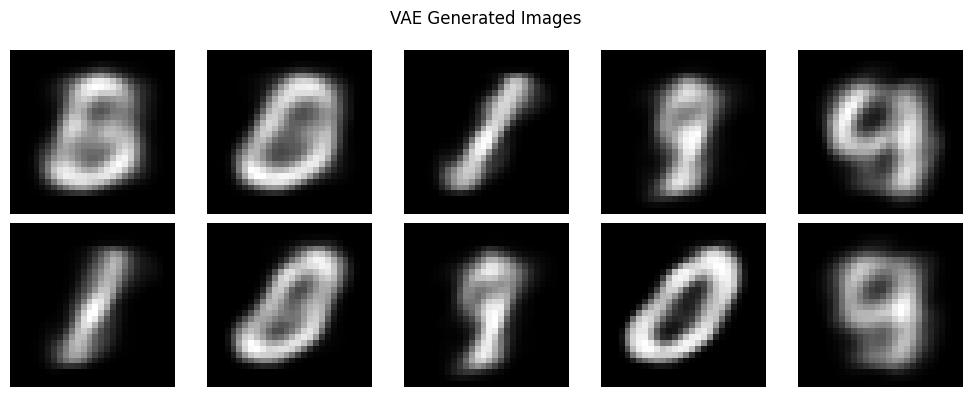

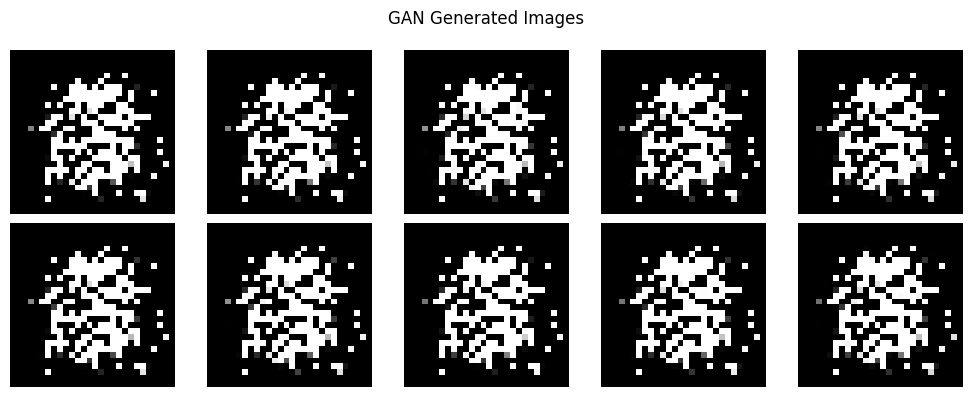


VAE and GAN image generation completed successfully!


In [ ]:
# EXPERIMENT 29: VAE AND GAN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

# 1. Load MNIST Dataset
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

# Normalize data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# 2. Build VAE Encoder
latent_dim = 2

encoder_input = keras.Input(shape=(784,))
x = layers.Dense(256, activation="relu")(encoder_input)

z_mean = layers.Dense(latent_dim)(x)
z_log_var = layers.Dense(latent_dim)(x)

class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(
    encoder_input,
    [z_mean, z_log_var, z],
    name="encoder"
)

# 3. Build VAE Decoder
decoder_input = keras.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(decoder_input)
decoder_output = layers.Dense(784, activation="sigmoid")(x)

decoder = keras.Model(
    decoder_input,
    decoder_output,
    name="decoder"
)

# 4. Create Custom VAE Model
class VAE(keras.Model):

    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            mean, log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_sum(
                keras.losses.binary_crossentropy(data, reconstruction),
                axis=-1
            )

            kl_loss = -0.5 * tf.reduce_sum(
                1 + log_var - tf.square(mean) - tf.exp(log_var),
                axis=-1
            )

            total_loss = tf.reduce_mean(
                reconstruction_loss + kl_loss
            )

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(
            tf.reduce_mean(reconstruction_loss)
        )
        self.kl_loss_tracker.update_state(tf.reduce_mean(kl_loss))

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

# Train VAE
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())

print("\nTraining VAE...")
vae.fit(x_train, epochs=3, batch_size=128)

# 5. Generate Images Using VAE
random_latent = tf.random.normal(shape=(10, latent_dim))
vae_generated = decoder.predict(random_latent, verbose=0)

# 6. Build GAN Generator
generator = keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(784, activation="sigmoid")
], name="generator")

# 7. Build GAN Discriminator
discriminator = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="discriminator")

# 8. Train GAN
optimizer_g = keras.optimizers.Adam(0.0002)
optimizer_d = keras.optimizers.Adam(0.0002)

loss_function = keras.losses.BinaryCrossentropy()

batch_size = 128
epochs = 3

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(batch_size)

print("\nTraining GAN...")

for epoch in range(epochs):

    for real_images in dataset:

        current_batch = tf.shape(real_images)[0]

        # Train Discriminator
        noise = tf.random.normal((current_batch, 100))

        with tf.GradientTape() as tape:

            fake_images = generator(noise, training=True)

            real_output = discriminator(
                real_images, training=True
            )

            fake_output = discriminator(
                tf.stop_gradient(fake_images), training=True
            )

            real_loss = loss_function(
                tf.ones_like(real_output), real_output
            )

            fake_loss = loss_function(
                tf.zeros_like(fake_output), fake_output
            )

            d_loss = real_loss + fake_loss

        d_gradients = tape.gradient(
            d_loss, discriminator.trainable_weights
        )

        optimizer_d.apply_gradients(
            zip(d_gradients, discriminator.trainable_weights)
        )

        # Train Generator
        noise = tf.random.normal((current_batch, 100))

        with tf.GradientTape() as tape:

            fake_images = generator(noise, training=True)
            fake_output = discriminator(
                fake_images, training=False
            )

            g_loss = loss_function(
                tf.ones_like(fake_output), fake_output
            )

        g_gradients = tape.gradient(
            g_loss, generator.trainable_weights
        )

        optimizer_g.apply_gradients(
            zip(g_gradients, generator.trainable_weights)
        )

    print(
        "Epoch:", epoch + 1,
        "Generator Loss:", float(g_loss),
        "Discriminator Loss:", float(d_loss)
    )

# 9. Generate Images Using GAN
noise = tf.random.normal((10, 100))
gan_generated = generator.predict(noise, verbose=0)

# 10. Display VAE Generated Images
plt.figure(figsize=(10, 4))
plt.suptitle("VAE Generated Images")

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(vae_generated[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 11. Display GAN Generated Images
plt.figure(figsize=(10, 4))
plt.suptitle("GAN Generated Images")

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(gan_generated[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\nVAE and GAN image generation completed successfully!")